In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()


In [2]:
data = pd.read_csv("D://DataSet/telco_churn.csv")

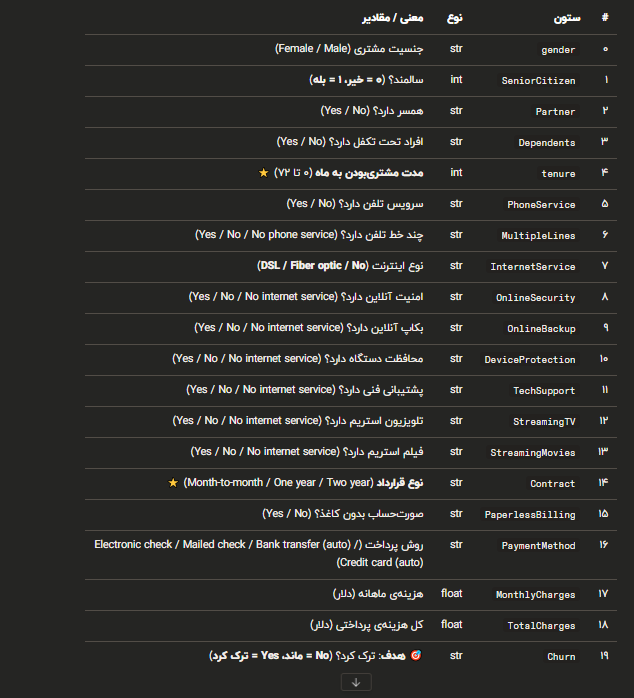

### Preprocessing

In [3]:
data.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [4]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [ ]:
data.isna().sum() / data.shape[0] * 100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

In [11]:
for i in data.select_dtypes("str") :
    print(i) 
    print(np.unique(data[i]))
    print(data[i].nunique())
    print("*"*100)

customerID
['0002-ORFBO' '0003-MKNFE' '0004-TLHLJ' ... '9992-UJOEL' '9993-LHIEB'
 '9995-HOTOH']
7043
****************************************************************************************************
gender
['Female' 'Male']
2
****************************************************************************************************
Partner
['No' 'Yes']
2
****************************************************************************************************
Dependents
['No' 'Yes']
2
****************************************************************************************************
PhoneService
['No' 'Yes']
2
****************************************************************************************************
MultipleLines
['No' 'No phone service' 'Yes']
3
****************************************************************************************************
InternetService
['DSL' 'Fiber optic' 'No']
3
************************************************************************************************

In [5]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data = data[data.TotalCharges != " "]
data.TotalCharges = pd.to_numeric(data.TotalCharges , errors="raise")

In [14]:
data.drop("customerID" , axis=1 , inplace=True)
# data.info()

### EDA 

- هدف کل : چه عواملی باعث میشن مشتری مخابراتی ترک کنه؟ — و شرکت چطور می‌تونه نگه‌ش داره؟

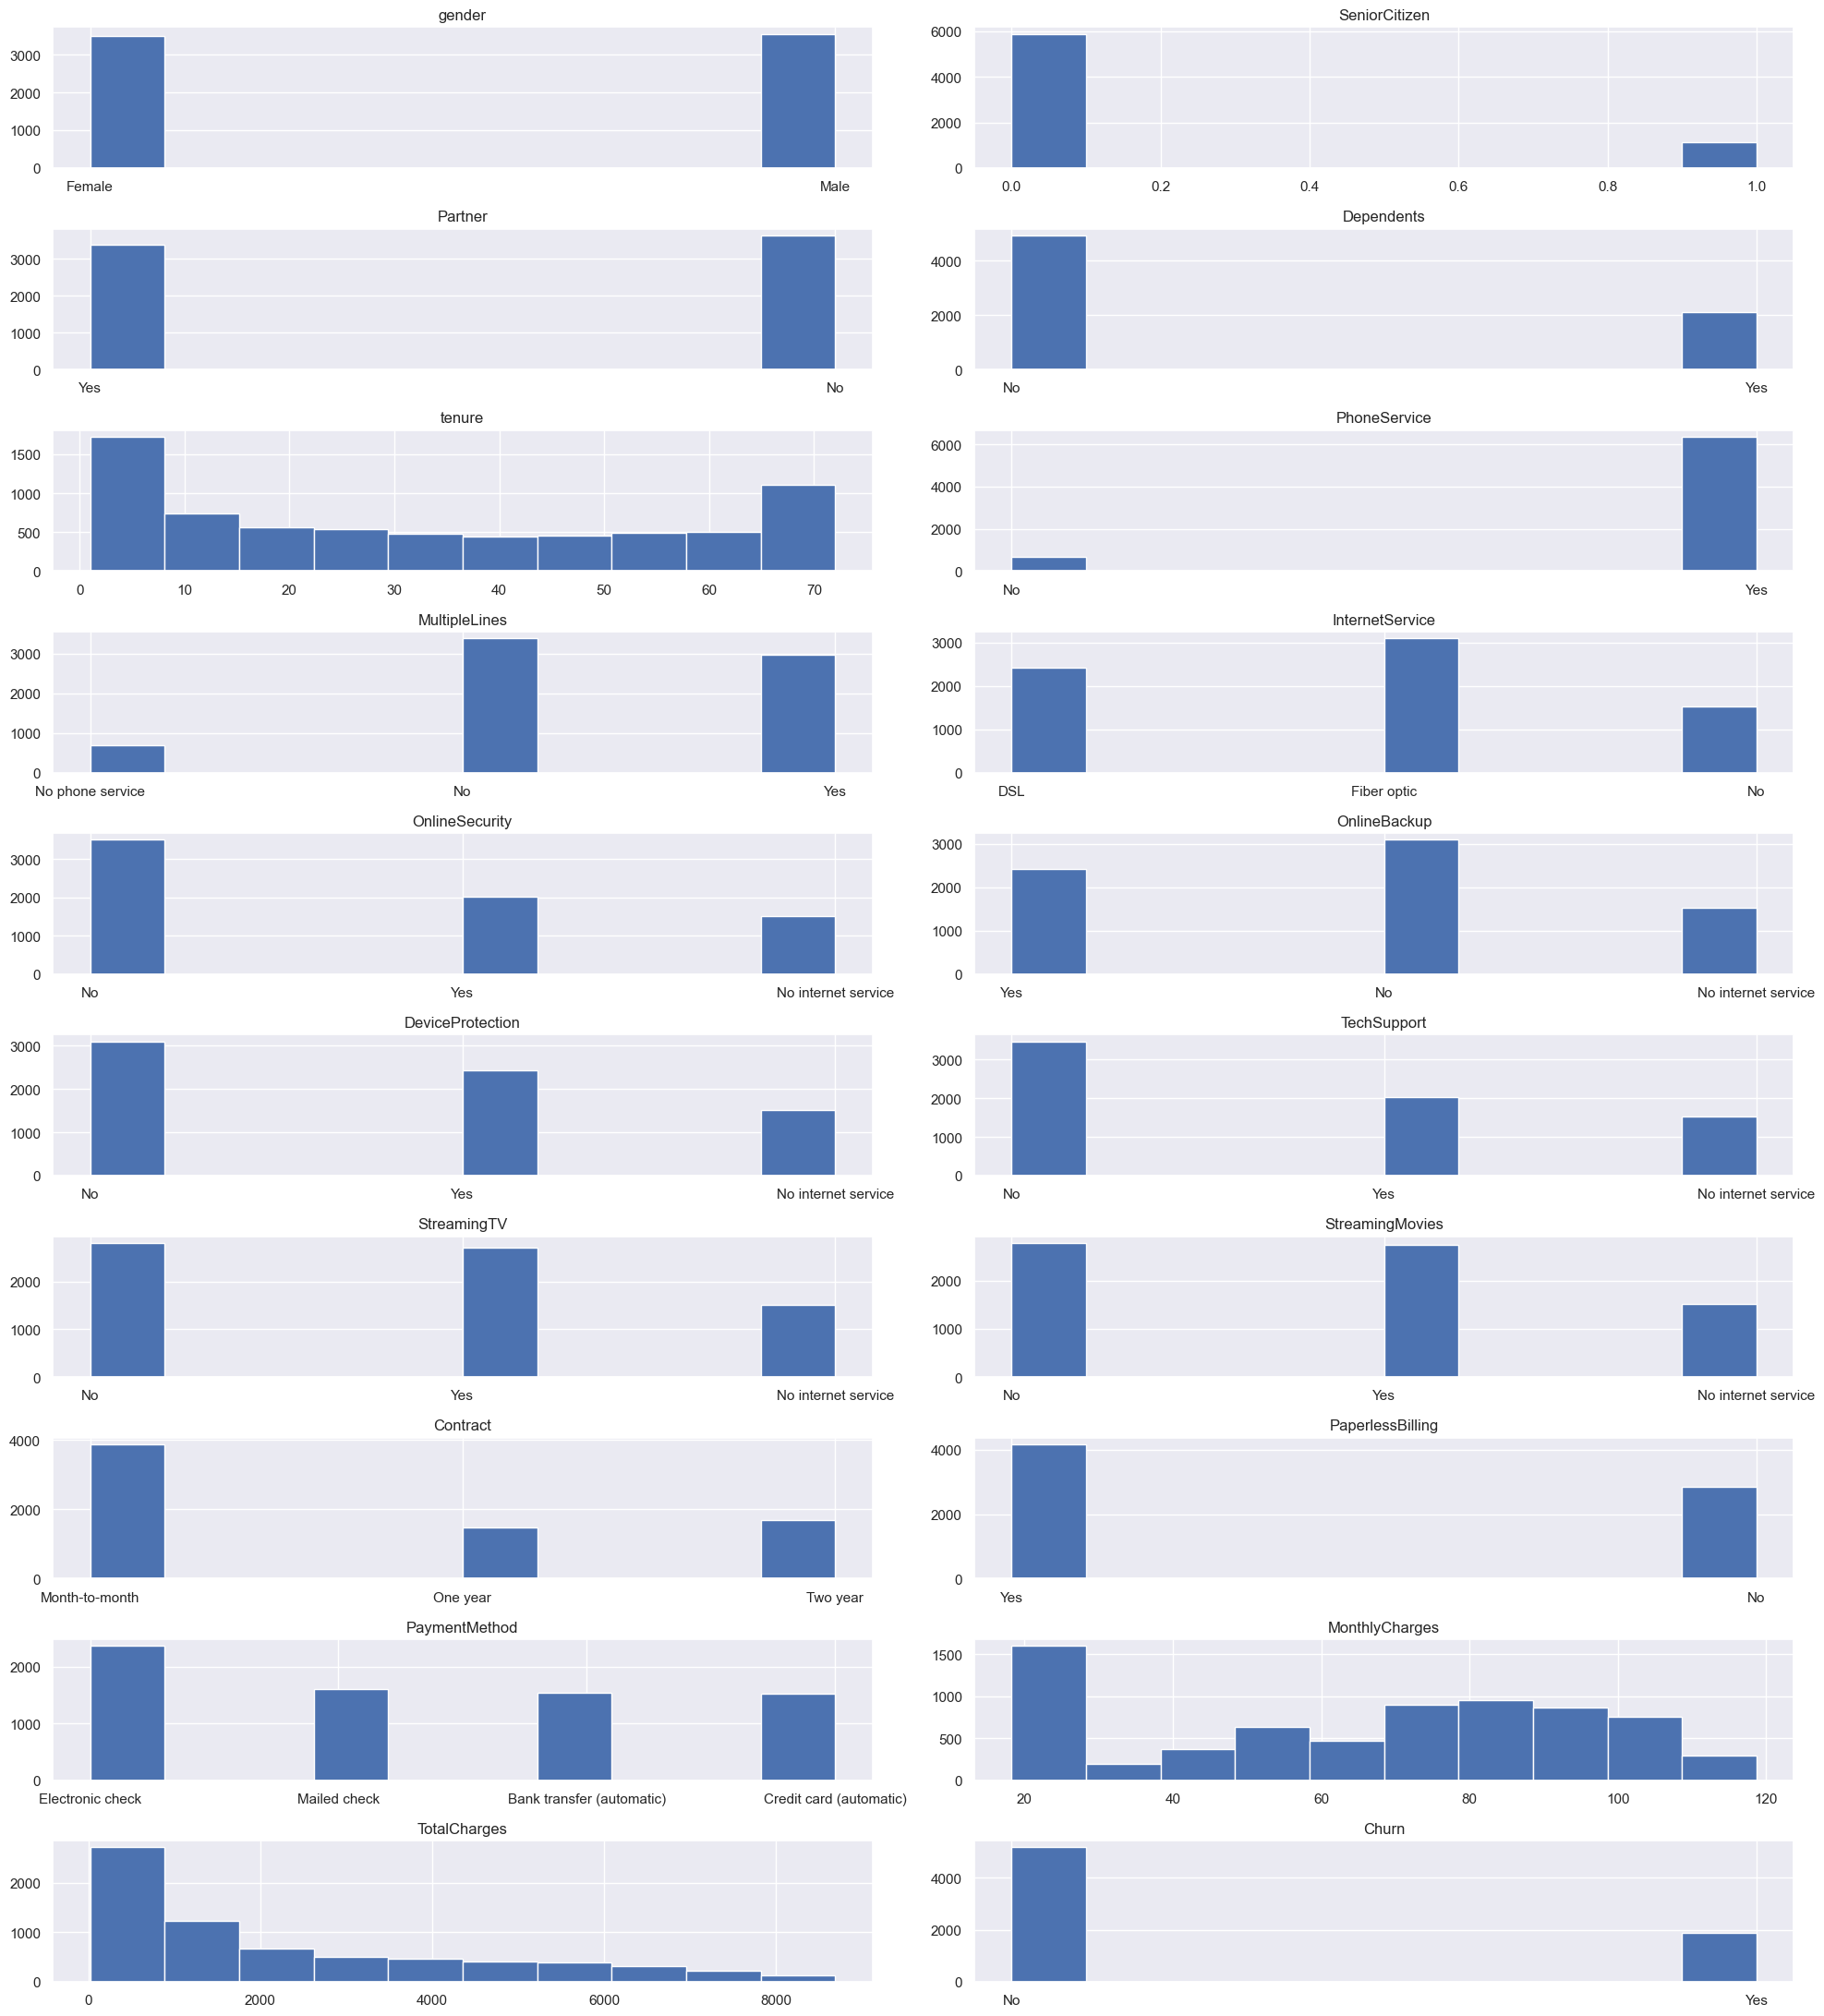

In [7]:
fig , axes = plt.subplots(10,2,figsize=[20,22])
axes = axes.flatten()


for i , col in enumerate(data) : 
    axes[i].hist(data[col])
    axes[i].set_title(col)
plt.tight_layout()

In [ ]:
list_ = ["tenure" , "MonthlyCharges" , "TotalCharges"]

for col in list_ : 
    print(f"{col} : " , data[col].skew())

    print(
        data[col].agg(["mean" , "median"])
    )
    print("-" * 100)
    

tenure :  0.23773083190513133
mean      32.421786
median    29.000000
Name: tenure, dtype: float64
----------------------------------------------------------------------------------------------------
MonthlyCharges :  -0.22210292770166232
mean      64.798208
median    70.350000
Name: MonthlyCharges, dtype: float64
----------------------------------------------------------------------------------------------------
TotalCharges :  0.9616424997242504
mean      2283.300441
median    1397.475000
Name: TotalCharges, dtype: float64
----------------------------------------------------------------------------------------------------


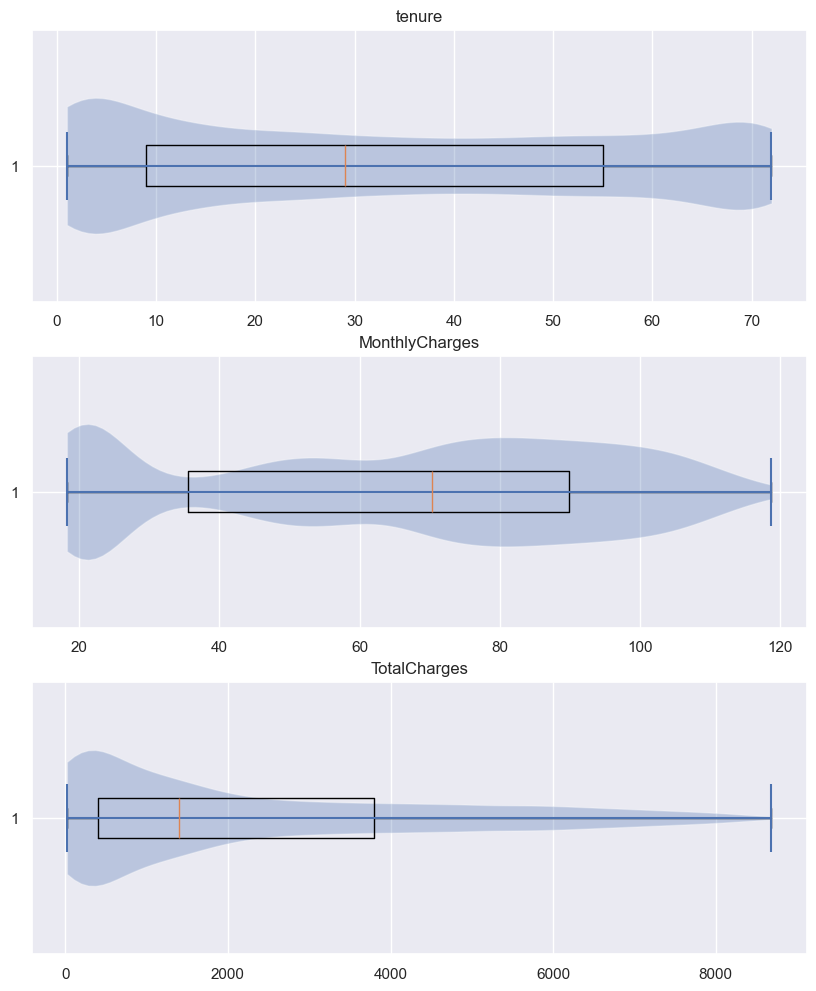

In [12]:
list_ = ["tenure" , "MonthlyCharges" , "TotalCharges"]

size , axes = plt.subplots(3,1,figsize=[10,12])
axes = axes.flatten()

for i , col in enumerate(list_) : 
    axes[i].boxplot(data[col] , vert=False) 
    axes[i].violinplot(data[col] , vert=False) 
    axes[i].set_title(col)



- نرخ مشتریان مانده و رفته 

In [ ]:
data['Churn'] = data['Churn'].map({'Yes':1, 'No':0})   


data["new_tenure"] = pd.cut(
    data["tenure"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=[
        "0-6 mo",
        "7-12 mo",
        "13-24 mo",
        "25-48 mo",
        "49-72 mo"
    ],
    include_lowest=True
)


# یا 

# def Churn(value) : 
#     if value == "Yes" : 
#         return 1
#     elif value == "No" : 
#         return 0
# data.Churn = data.Churn.apply(Churn)

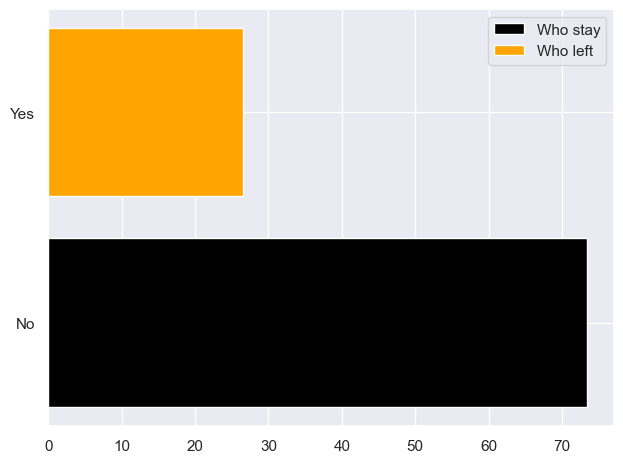

In [ ]:
plt.barh(["No" , "Yes" ] , [(1 - data.Churn.mean()) * 100 , (data.Churn.mean()) * 100] , color=["black" , "orange"] ,
    label=["Who stay" , "Who left"]
         );
plt.tight_layout()
plt.legend();

- آیا زن یا مرد بودن در ترک کردن تاثیر دارد 

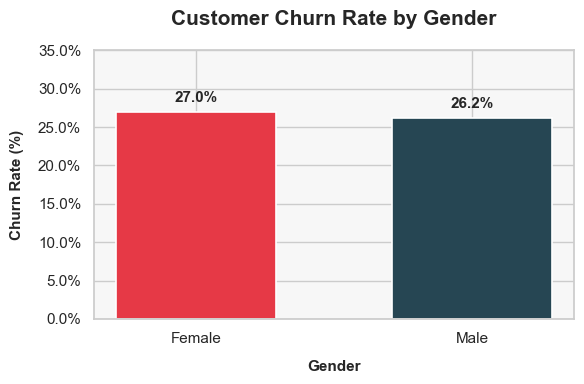

In [13]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#F7F7F7",
        "figure.facecolor": "white"
    }
)

# محاسبه نرخ ترک
gender_churn = (
    data.groupby("gender")["Churn"]
    .mean()
    .mul(100)
    .reindex(["Female", "Male"])
)

# رنگ قرمز برای گروه دارای نرخ ترک بیشتر
colors = [
    "#E63946" if value == gender_churn.max()
    else "#264653"
    for value in gender_churn
]

fig, ax = plt.subplots(
    figsize=(6, 4)
)

bars = ax.bar(
    gender_churn.index,
    gender_churn.values,
    width=0.58,
    color=colors,
    edgecolor="white",
    linewidth=1.2
)

# نوشتن درصد روی میله‌ها
ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in gender_churn
    ],
    padding=5,
    fontsize=11,
    fontweight="bold"
)

# میانگین کلی نرخ ترک
overall_churn = data["Churn"].mean() * 100


ax.set_title(
    "Customer Churn Rate by Gender",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Gender",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.set_ylim(
    0,
    max(
        gender_churn.max(),
        overall_churn
    ) * 1.3
)



plt.tight_layout()


- آیا محافظ دستگاه در ترک تاثیری دارد 

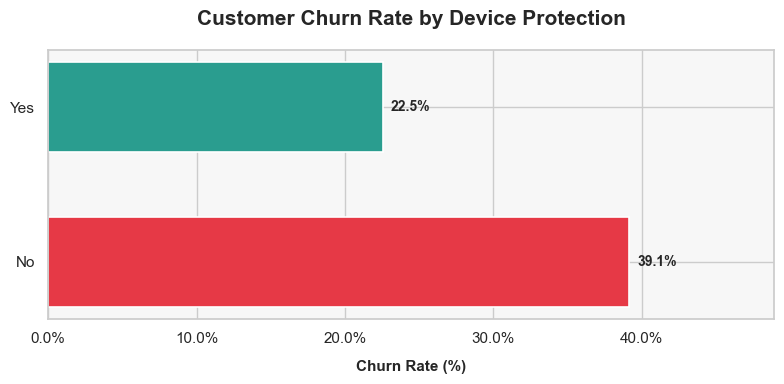

In [14]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#F7F7F7",
        "figure.facecolor": "white"
    }
)

category_order = [
    "No",
    "Yes"
]

# محاسبه نرخ ترک
device_churn = (
    data.groupby("DeviceProtection")["Churn"]
    .mean()
    .mul(100)
    .reindex(category_order)
)

category_colors = {
    "No": "#E63946",
    "Yes": "#2A9D8F",
}

colors = [
    category_colors[category]
    for category in device_churn.index
]

fig, ax = plt.subplots(
    figsize=(8, 4)
)

bars = ax.barh(
    device_churn.index,
    device_churn.values,
    height=0.58,
    color=colors,
    edgecolor="white",
    linewidth=1.2
)

# نوشتن درصد کنار میله‌ها
ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in device_churn
    ],
    padding=6,
    fontsize=10,
    fontweight="bold"
)

ax.set_title(
    "Customer Churn Rate by Device Protection",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)


ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.set_xlim(
    0,
    max(
        device_churn.max(),
        overall_churn
    ) * 1.25
)


plt.tight_layout()


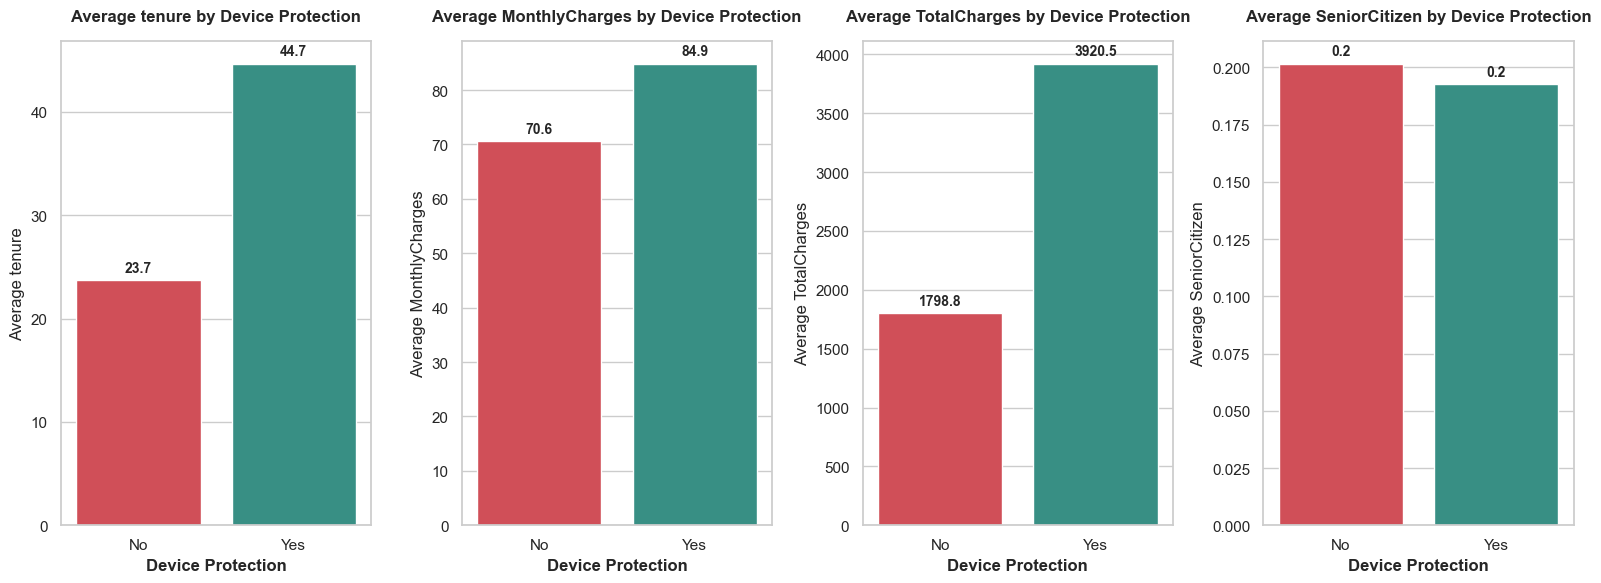

In [74]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges" , 
    "SeniorCitizen"
]

device_users = data[
    data["DeviceProtection"].isin(["No", "Yes"])
]

palette = {
    "No": "#E63946",
    "Yes": "#2A9D8F"
}

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 6)
)

for ax, column in zip(
    axes,
    numeric_columns
):

    sns.barplot(
        data=device_users,
        x="DeviceProtection",
        y=column,
        order=["No", "Yes"],
        hue="DeviceProtection",
        hue_order=["No", "Yes"],
        palette=palette,
        estimator="mean",
        errorbar=None,
        ax=ax
    )

    # نوشتن میانگین روی میله‌ها
    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%.1f",
            padding=4,
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(
        f"Average {column} by Device Protection",
        fontsize=12,
        fontweight="bold",
        pad=14
    )

    ax.set_xlabel(
        "Device Protection",
        fontweight="bold"
    )

    ax.set_ylabel(
        f"Average {column}"
    )

plt.tight_layout()

- آزمون آماری 


- Cramér's V :
    - 0.10 → ارتباط ضعیف
    - 0.30 → ارتباط متوسط
    - 0.50 → ارتباط قوی

In [83]:
from scipy.stats import chi2_contingency

test_data = data[data.DeviceProtection.isin(["Yes" , "No"])] # مهم

observed = pd.crosstab(
    test_data["SeniorCitizen"],
    test_data["DeviceProtection"]
)

chi2, p_value, dof, expected = chi2_contingency(observed)
print(f"P-value: {p_value:.3e}")


n = observed.to_numpy().sum()
rows, columns = observed.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)


print(f"Cramer's V: {cramers_v:.3f}")   


P-value: 4.268e-01
Cramer's V: 0.011


- H0: توزیع و رتبه‌های متغیر عددی در دو گروه یکسان است
- Rank-biserial : 
    - کمتر از 0.10 → ناچیز
    - 0.10 تا 0.30 → ضعیف
    - 0.30 تا 0.50 → متوسط
    - 0.50 به بالا → قوی


- Bonferroni : وقتی چند آزمون آماری انجام می‌دهیم، احتمال اینکه حداقل یکی از آن‌ها به‌اشتباه معنادار شود افزایش پیدا می‌کند
-  استفاده می‌کنیم تا هنگام اجرای چند آزمون، ارتباطی را صرفاً بر اثر شانس و به‌اشتباه معنادار تشخیص ندهیم

In [85]:
from scipy.stats import mannwhitneyu

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

number_of_tests = len(numeric_columns)

for column in numeric_columns:

    test_data = data.loc[
        data["DeviceProtection"].isin(["No", "Yes"]),
        ["DeviceProtection", column]
    ].dropna()

    yes_group = test_data.loc[
        test_data["DeviceProtection"] == "Yes",
        column
    ]

    no_group = test_data.loc[
        test_data["DeviceProtection"] == "No",
        column
    ]

    # بررسی خالی‌نبودن گروه‌ها
    if len(yes_group) == 0 or len(no_group) == 0:
        print(f"{column}: یکی از گروه‌ها خالی است.")
        continue

    # آزمون Mann–Whitney U
    u_statistic, p_value = mannwhitneyu(
        yes_group,
        no_group,
        alternative="two-sided",
        method="asymptotic"
    )

    # اصلاح Bonferroni برای سه آزمون
    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    # اندازه اثر
    rank_biserial = (
        2 * u_statistic
        / (len(yes_group) * len(no_group))
        - 1
    )

    effect_size = abs(rank_biserial)

    print(column)
    print(f"Raw p-value: {p_value:.3e}")
    print(f"adjusted_p : {adjusted_p}")
    print(f"Rank-biserial: {rank_biserial:.3f}")
    print("-" * 100)

tenure
Raw p-value: 1.555e-221
adjusted_p : 4.664377671379104e-221
Rank-biserial: 0.498
----------------------------------------------------------------------------------------------------
MonthlyCharges
Raw p-value: 2.182e-129
adjusted_p : 6.545276250312616e-129
Rank-biserial: 0.379
----------------------------------------------------------------------------------------------------
TotalCharges
Raw p-value: 5.549e-246
adjusted_p : 1.6646792156536345e-245
Rank-biserial: 0.525
----------------------------------------------------------------------------------------------------


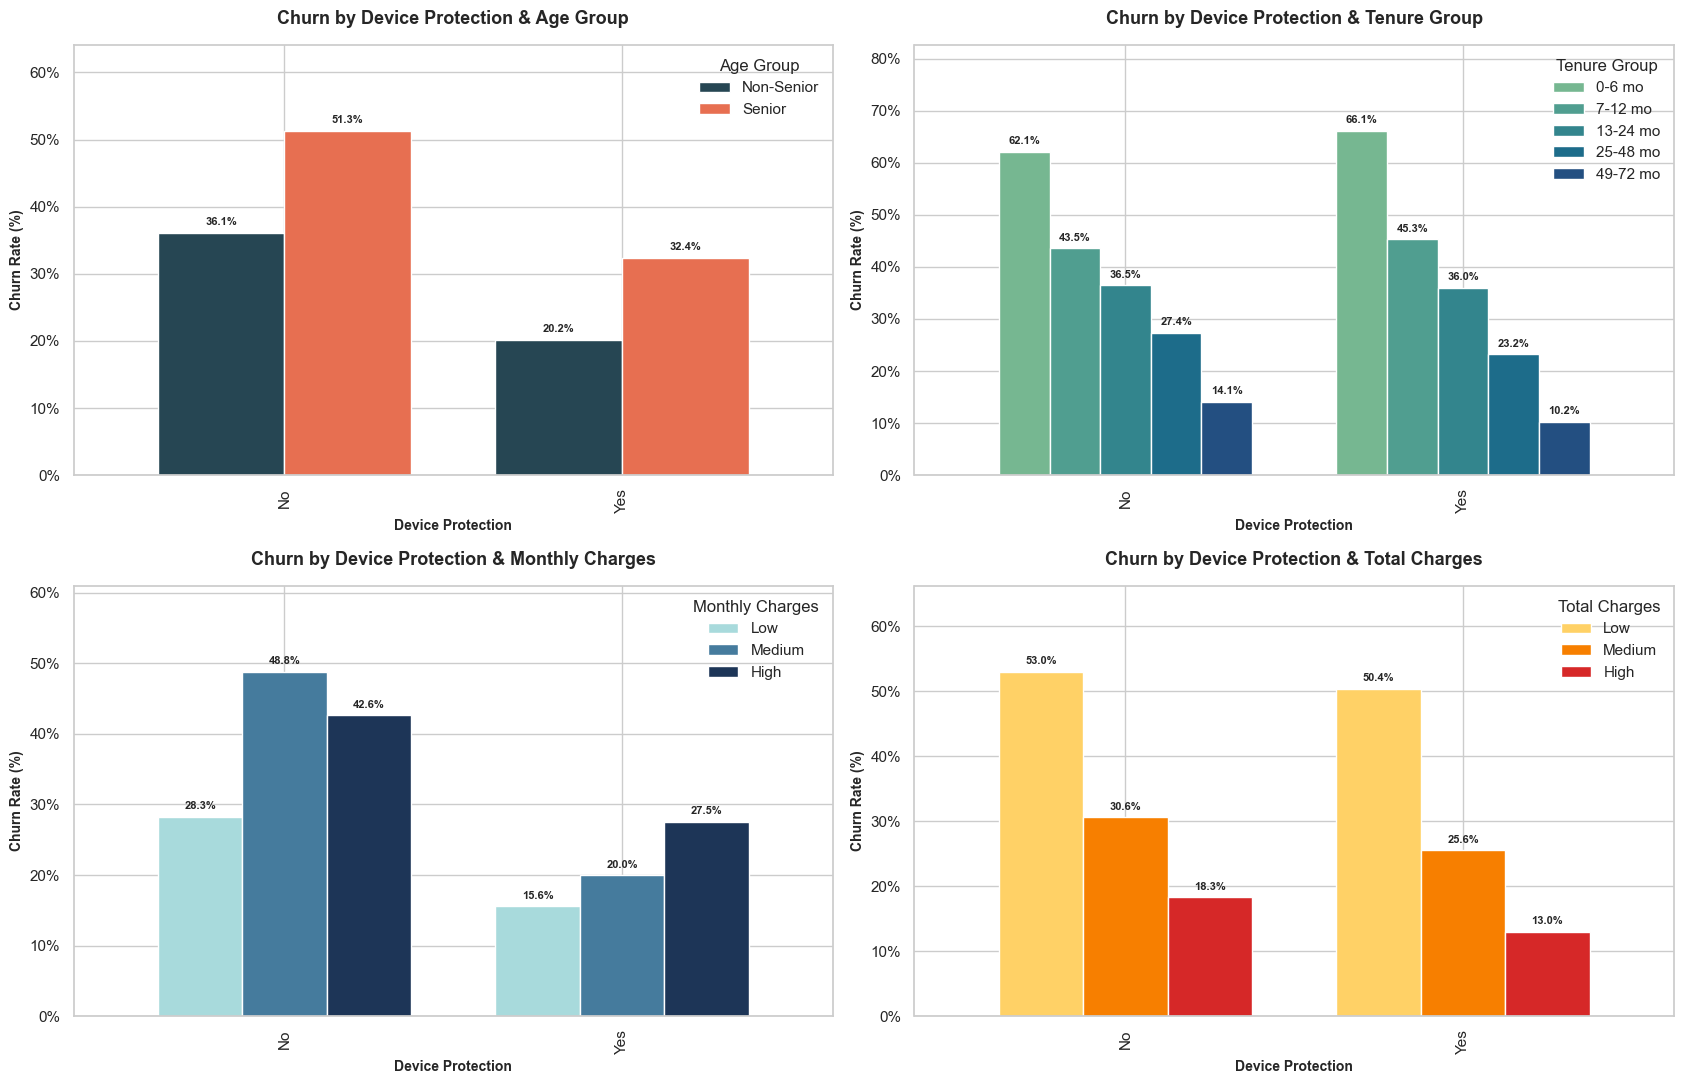

In [86]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")

# فقط افراد دارای اینترنت
df = data.loc[
    data["DeviceProtection"].isin(["No", "Yes"])
].copy()

# اطمینان از عددی‌بودن
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# گروه‌بندی tenure
tenure_labels = [
    "0-6 mo",
    "7-12 mo",
    "13-24 mo",
    "25-48 mo",
    "49-72 mo"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 6, 12, 24, 48, np.inf],
    labels=tenure_labels,
    include_lowest=True
)

# گروه‌بندی هزینه‌ها
charge_labels = [
    "Low",
    "Medium",
    "High"
]

df["MonthlyGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=3,
    labels=charge_labels
)

df["TotalGroup"] = pd.qcut(
    df["TotalCharges"],
    q=3,
    labels=charge_labels
)

# تنظیمات نمودارها
plot_settings = [
    (
        "SeniorCitizen",
        "Age Group",
        ["#264653", "#E76F51"]
    ),
    (
        "TenureGroup",
        "Tenure Group",
        sns.color_palette("crest", 5)
    ),
    (
        "MonthlyGroup",
        "Monthly Charges",
        ["#A8DADC", "#457B9D", "#1D3557"]
    ),
    (
        "TotalGroup",
        "Total Charges",
        ["#FFD166", "#F77F00", "#D62828"]
    )
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11)
)

axes = axes.flatten()

for ax, (column, title, colors) in zip(
    axes,
    plot_settings
):

    result = df.pivot_table(
        index="DeviceProtection",
        columns=column,
        values="Churn",
        aggfunc="mean",
        observed=False
    ).mul(100)

    result = result.reindex(
        ["No", "Yes"]
    )

    # تغییر نام فقط برای SeniorCitizen
    if column == "SeniorCitizen":

        result = result.rename(
            columns={
                0: "Non-Senior",
                1: "Senior"
            }
        )

    result.plot(
        kind="bar",
        ax=ax,
        width=0.75,
        color=colors,
        edgecolor="white",
        linewidth=1
    )

    # نوشتن درصد روی میله‌ها
    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=4,
            fontsize=8,
            fontweight="bold"
        )

    ax.set_title(
        f"Churn by Device Protection & {title}",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Device Protection",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Churn Rate (%)",
        fontsize=10,
        fontweight="bold"
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.set_ylim(
        0,
        min(
            100,
            result.max().max() * 1.25
        )
    )

    ax.legend(
        title=title,
        frameon=False,
        fontsize=11
    )


plt.tight_layout()


- آیا نوعِ قرارداد روی ترک کردن مشتریان تاثیر داره؟

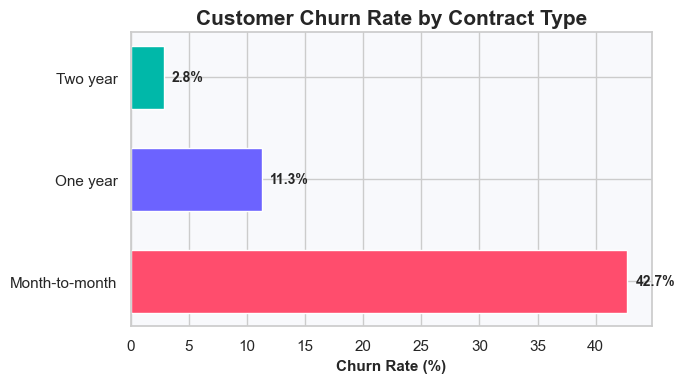

In [94]:
from matplotlib.ticker import PercentFormatter


contract_order = [
    "Month-to-month",
    "One year",
    "Two year"
]

contract_colors = {
    "Month-to-month": "#FF4D6D",
    "One year": "#6C63FF",
    "Two year": "#00B8A9"
}

a = (
    data.groupby("Contract")["Churn"]
    .mean()
    .mul(100)
    .reindex(contract_order)
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

bars = ax.barh(
    a["Contract"],
    a["Churn"],
    height=0.62,
    color=[
        contract_colors[contract]
        for contract in a["Contract"]
    ],
)

# نوشتن درصد کنار میله‌ها
ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in a["Churn"]
    ],
    padding=6,
    fontsize=10,
    fontweight="bold"
)

ax.set_title(
    "Customer Churn Rate by Contract Type",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
)


plt.tight_layout()


- عواملی که احتمالا در دلیل ترک بیشتر در قرار داد ماه به ماه تاثیر دارند 

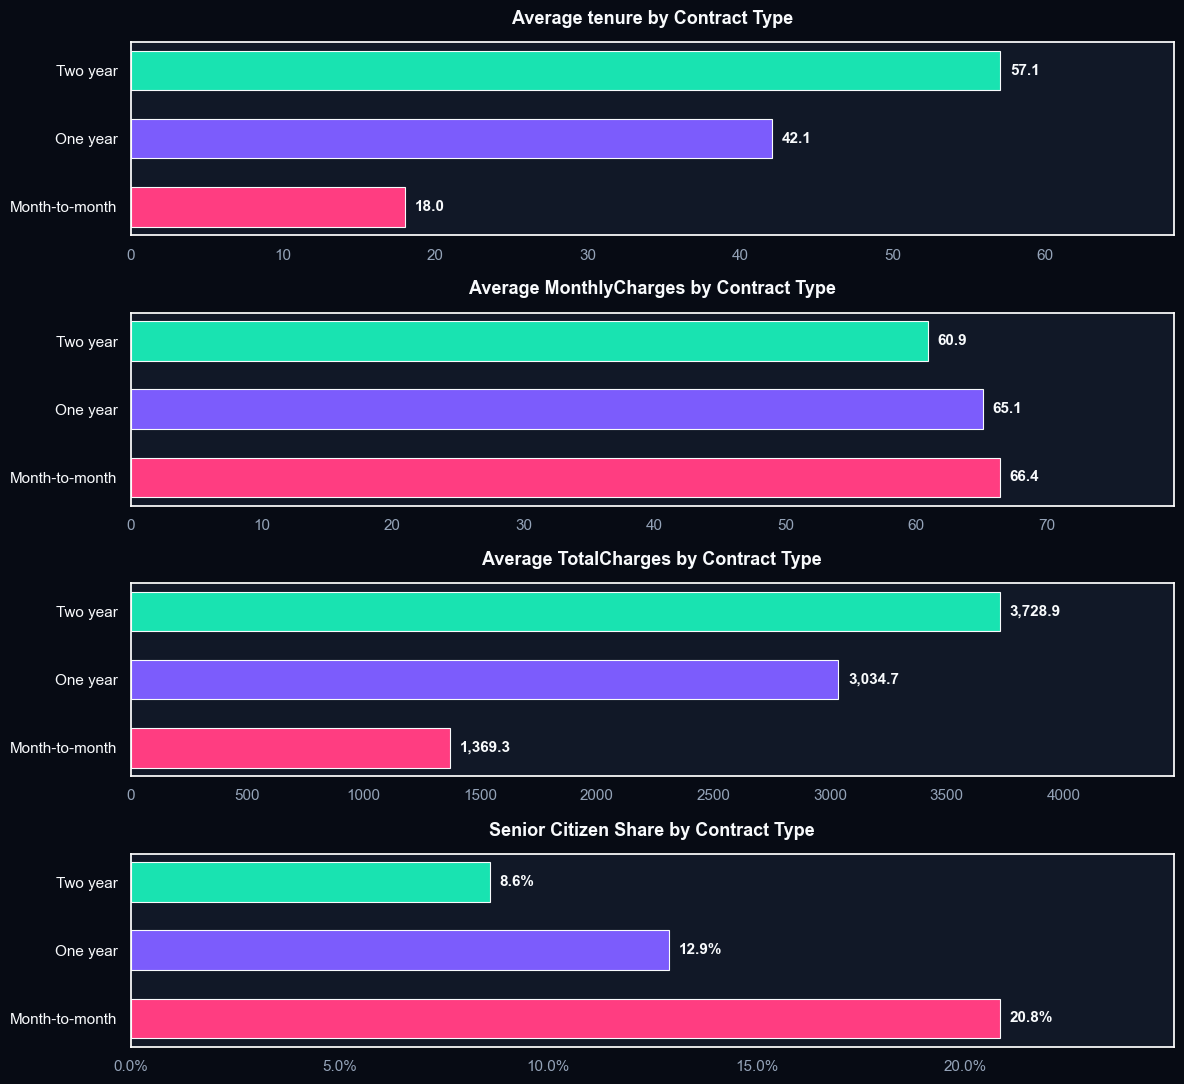

In [141]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="darkgrid") # رنگ بک گراند

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

contract_order = [
    "Month-to-month",
    "One year",
    "Two year"
]

contract_palette = {
    "Month-to-month": "#FF3D81",  
    "One year": "#7C5CFC",        
    "Two year": "#19E3B1"         
}

fig, axes = plt.subplots(
    4,
    1,
    figsize=(12, 11),
    facecolor="#070B14"
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    numeric_columns
):

    result = (
        data.groupby("Contract")[column]
        .mean()
        .reindex(contract_order)
    )

    colors = [
        contract_palette[contract]
        for contract in result.index
    ]

    bars = ax.barh(
        result.index,
        result.values,
        height=0.58,
        color=colors,
        edgecolor="#F8FAFC",
        linewidth=0.8
    )

    # فرمت مخصوص SeniorCitizen
    if column == "SeniorCitizen":

        labels = [
            f"{value:.1%}"
            for value in result.values
        ]

        ax.xaxis.set_major_formatter(
            PercentFormatter(xmax=1)
        )

        title = (
            "Senior Citizen Share "
            "by Contract Type"
        )

    else:

        labels = [
            f"{value:,.1f}"
            for value in result.values
        ]

        title = (
            f"Average {column} "
            f"by Contract Type"
        )

    ax.bar_label(
        bars,
        labels=labels,
        padding=7,
        fontsize=11,
        fontweight="bold",
        color="#F8FAFC"
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color="#F8FAFC",
        pad=13
    )

    ax.set_xlim(
        0,
        result.max() * 1.20
    )

    ax.tick_params(
        axis="x",
        colors="#94A3B8" # رنگ های نوشته هر گروه
    )

    ax.tick_params(
        axis="y",
        colors="#F8FAFC", # رنگ های نوشته هر گروه
        labelsize=11
    )
    ax.grid(visible=False)
    ax.set_facecolor("#111827") # رنگ داخل نمودار

plt.tight_layout()


- سه عامل تاثیر گذار در نوع قرار داد 

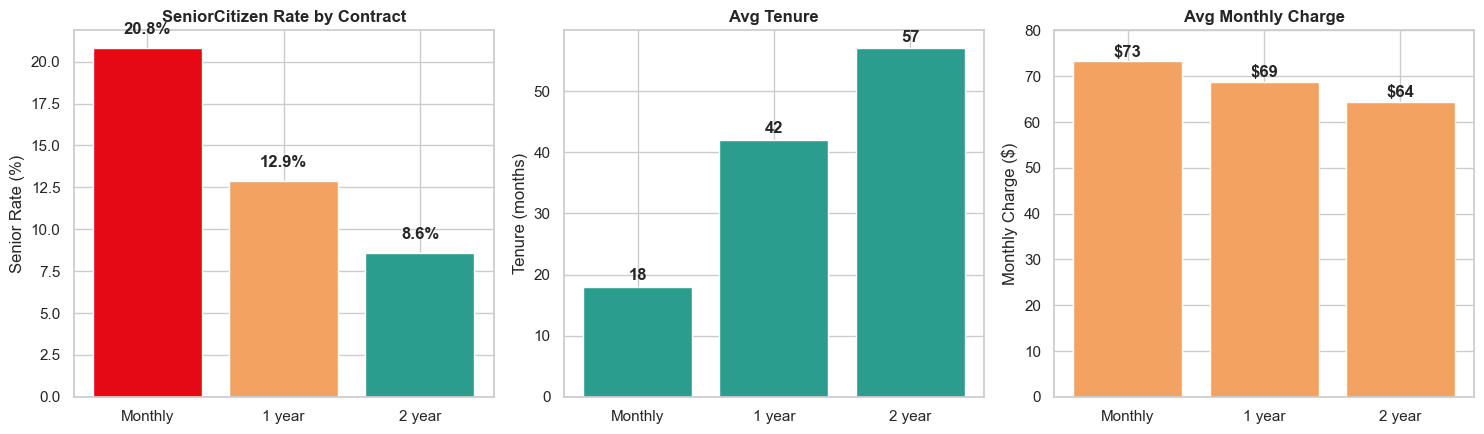

In [25]:
order = ["Month-to-month", "One year", "Two year"]

churn  = (data.groupby("Contract")["SeniorCitizen"].mean() * 100).reindex(order)  
tenure = data.groupby("Contract")["tenure"].mean().reindex(order)              
monthly = data.groupby("Contract")["MonthlyCharges"].median().reindex(order) 

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].bar(range(3), churn.values, color=["#E50914", "#f4a261", "#2a9d8f"])
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["Monthly", "1 year", "2 year"])
axes[0].set_title("SeniorCitizen Rate by Contract", fontweight="bold")
axes[0].set_ylabel("Senior Rate (%)")
for i, v in enumerate(churn.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")

axes[1].bar(range(3), tenure.values, color="#2a9d8f")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(["Monthly", "1 year", "2 year"])
axes[1].set_title("Avg Tenure", fontweight="bold")
axes[1].set_ylabel("Tenure (months)")
for i, v in enumerate(tenure.values):
    axes[1].text(i, v + 1, f"{v:.0f}", ha="center", fontweight="bold")

axes[2].bar(range(3), monthly.values, color="#f4a261")
axes[2].set_xticks(range(3)); axes[2].set_xticklabels(["Monthly", "1 year", "2 year"])
axes[2].set_title("Avg Monthly Charge", fontweight="bold")
axes[2].set_ylabel("Monthly Charge ($)")
axes[2].set_ylim(0, 80)
for i, v in enumerate(monthly.values):
    axes[2].text(i, v + 1, f"${v:.0f}", ha="center", fontweight="bold")

plt.tight_layout()

- آیا سالمند بودن واقعا روی انتخاب قرار داد تاثیر دارد ؟ 

In [129]:
from scipy.stats import chi2_contingency

observed = pd.crosstab(
    data["SeniorCitizen"],
    data["Contract"]
)

chi2, p_value, dof, expected = chi2_contingency(observed)

print(observed)
print(f"\nChi-square: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"Expected : {expected}")
print(f"P-value: {p_value:.3e}")

n = observed.to_numpy().sum()
rows, columns = observed.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)

print(f"Cramer's V: {cramers_v:.3f}")


Contract       Month-to-month  One year  Two year
SeniorCitizen                                    
0                        3068      1282      1540
1                         807       190       145

Chi-square: 144.127
Degrees of freedom: 2
Expected : [[3245.69823663 1232.94653015 1411.35523322]
 [ 629.30176337  239.05346985  273.64476678]]
P-value: 5.048e-32
Cramer's V: 0.143


- آیا سالمند بودن مشتریان واقعا در ترک کردن تاثیر گذار است ؟ 

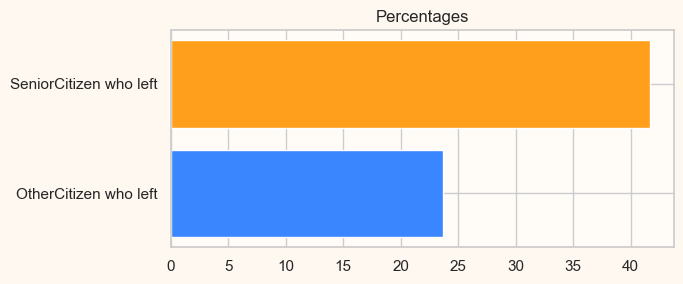

In [151]:
plt.figure(figsize=[7,3])

a = data.groupby("SeniorCitizen").Churn.mean() * 100
a = a.reset_index()
plt.barh(["OtherCitizen who left" , "SeniorCitizen who left"] , a.Churn , color=["#3A86FF" , "#FF9F1C"])
plt.title("Percentages")
plt.tight_layout()


- آیا مشتری قدیمی یا جدید بودن واقعا در ترک کردن اثر دارد ؟ 

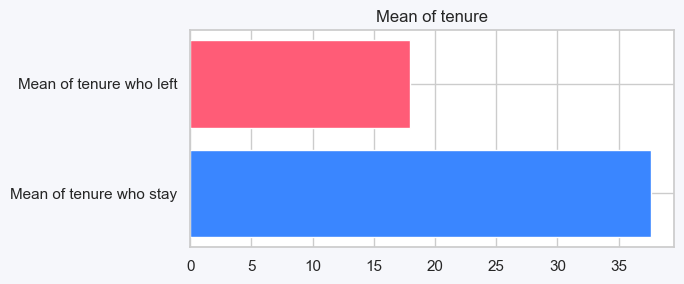

In [155]:
plt.figure(figsize=[7,3])

a = data.groupby("Churn").tenure.mean().reset_index()
plt.barh(["Mean of tenure who stay" , "Mean of tenure who left"] , a.tenure , color=["#3A86FF" , "#FF5C77"]);
plt.title("Mean of tenure");
plt.tight_layout()


- کدام بازه زمانی از مشتریان بیشتر از همه ترک میکنند ؟ 

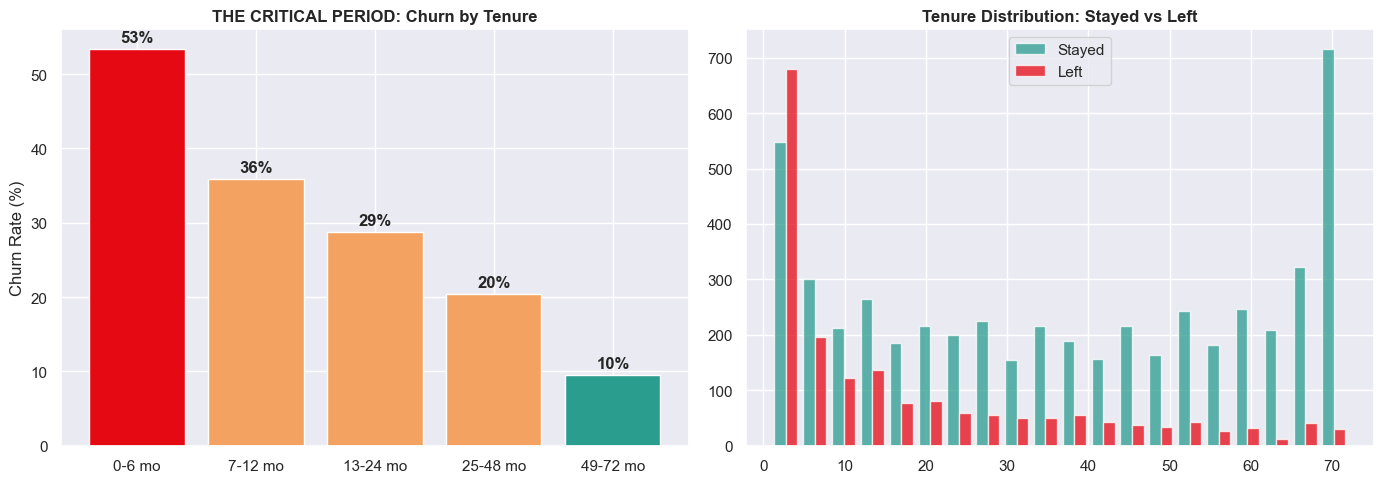

In [126]:
data["new_tenure"] = pd.cut(
    data["tenure"] , 
    bins=[0 , 6 , 12 , 24 , 48 , 72] , 
    labels=["0-6 mo" , "7-12 mo" , "13-24 mo" , "25-48 mo" , "49-72 mo"]
)

churn = data.groupby("new_tenure")["Churn"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ["#E50914" if v > 40 else "#f4a261" if v >  20 else "#2a9d8f"
          for v in churn.values]

axes[0].bar(range(5), churn.values, color=colors)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(churn.index)
axes[0].set_title("THE CRITICAL PERIOD: Churn by Tenure", fontweight="bold")
axes[0].set_ylabel("Churn Rate (%)")
for i, v in enumerate(churn.values):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")



stayed = data[data["Churn"] == 0]["tenure"]
left = data[data["Churn"] == 1]["tenure"]

axes[1].hist([stayed, left], bins=20, label=["Stayed", "Left"],
             color=["#2a9d8f", "#E50914"], alpha=0.75)
axes[1].set_title("Tenure Distribution: Stayed vs Left", fontweight="bold")
axes[1].legend()

plt.tight_layout()

- پیر بودن و مدت زمان مشتری چقدر تاثیر گذار است

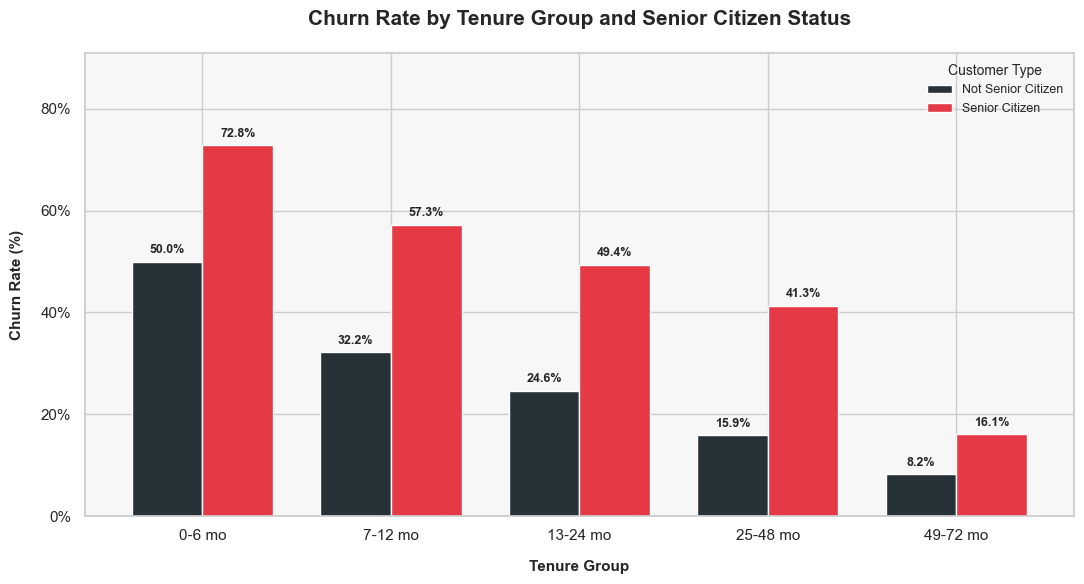

In [61]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#F7F7F7",
        "figure.facecolor": "white"
    }
)

# ساخت جدول نرخ ترک
churn_by_tenure = data.pivot_table(
    index="new_tenure",
    columns="SeniorCitizen",
    values="Churn",
    aggfunc="mean"
).mul(100)

# تغییر نام ستون‌ها
churn_by_tenure = (
    churn_by_tenure.rename(
        columns={
            0: "Not Senior Citizen",
            1: "Senior Citizen"
        }
    )
    [["Not Senior Citizen", "Senior Citizen"]]
)

# ساخت نمودار
fig, ax = plt.subplots(
    figsize=(11, 6)
)

churn_by_tenure.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    color=["#263238", "#E63946"],
    edgecolor="white",
    linewidth=1
)

# نوشتن درصد روی میله‌ها
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontsize=9,
        fontweight="bold"
    )

# عنوان و نام محورها
ax.set_title(
    "Churn Rate by Tenure Group and Senior Citizen Status",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Tenure Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

# نمایش محور عمودی به‌صورت درصد
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

# ایجاد فضای کافی بالای میله‌ها
ax.set_ylim(
    0,
    min(
        100,
        churn_by_tenure.max().max() * 1.25
    )
)

# تنظیم برچسب‌های محور افقی
ax.tick_params(
    axis="x",
    rotation=0
)

# تنظیم Legend
ax.legend(
    title="Customer Type",
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    loc="upper right"
)

plt.tight_layout()

- آیا نوع اینترنت روی ترک کردن مشتری ها تاثیر دارد ؟ 

Text(0.5, 1.0, 'percentages of left')

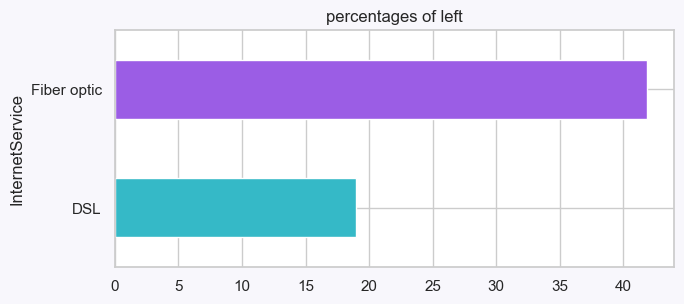

In [158]:
plt.figure(figsize=[7,3])

a = data.groupby("InternetService").Churn.mean()
a = a * 100
a.drop("No" , axis=0 , inplace=True)
a.plot.barh(color=["#35B9C7" , "#9B5DE5"])
plt.tight_layout()
plt.title("percentages of left")


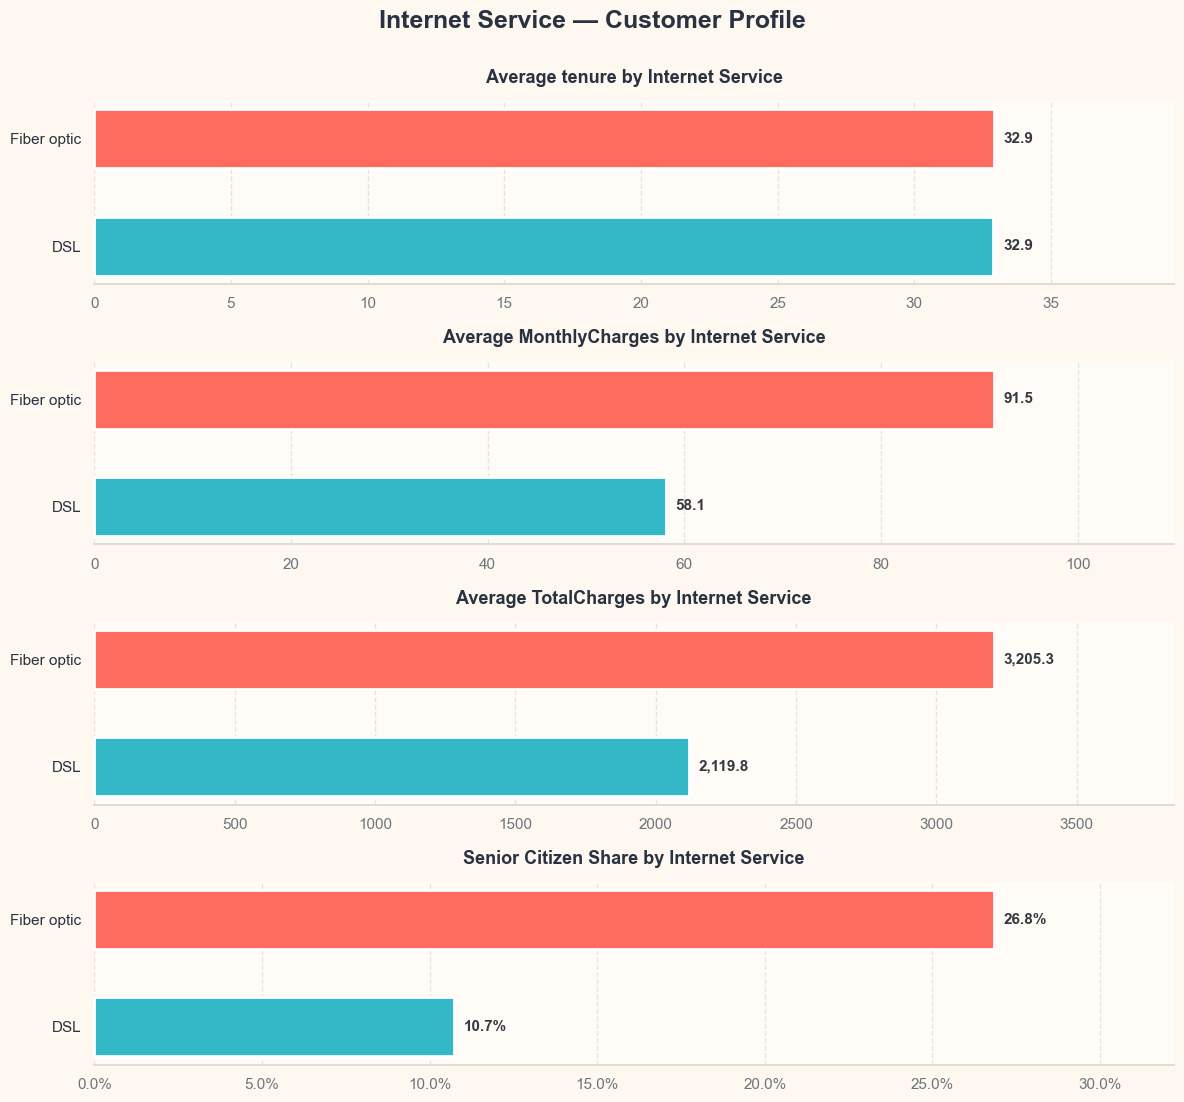

In [140]:
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#FFF8F0",
        "axes.facecolor": "#FFFCF8"
    }
)

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

internet_order = [
    "DSL",
    "Fiber optic"
]

internet_palette = {
    "DSL": "#32B8C6",
    "Fiber optic": "#FF6B5E"
}

internet_users = data[
    data["InternetService"].isin(
        internet_order
    )
]

fig, axes = plt.subplots(
    4,
    1,
    figsize=(12, 11),
    facecolor="#FFF8F0"
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    numeric_columns
):

    result = (
        internet_users.groupby("InternetService")[column]
        .mean()
        .reindex(internet_order)
    )

    colors = [
        internet_palette[internet]
        for internet in result.index
    ]

    bars = ax.barh(
        result.index,
        result.values,
        height=0.55,
        color=colors,
        edgecolor="white",
        linewidth=2
    )

    if column == "SeniorCitizen":

        labels = [
            f"{value:.1%}"
            for value in result.values
        ]

        ax.xaxis.set_major_formatter(
            PercentFormatter(xmax=1)
        )

        title = (
            "Senior Citizen Share "
            "by Internet Service"
        )

    else:

        labels = [
            f"{value:,.1f}"
            for value in result.values
        ]

        title = (
            f"Average {column} "
            f"by Internet Service"
        )

    ax.bar_label(
        bars,
        labels=labels,
        padding=7,
        fontsize=11,
        fontweight="bold",
        color="#343A40"
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color="#293241",
        pad=13
    )

    ax.set_xlim(
        0,
        result.max() * 1.20
    )

    ax.tick_params(
        axis="x",
        colors="#6C757D"
    )

    ax.tick_params(
        axis="y",
        colors="#293241",
        labelsize=11
    )

    ax.set_facecolor("#FFFCF8")

    ax.grid(
        axis="x",
        color="#DED7CE",
        linestyle="--",
        alpha=0.65
    )

    ax.grid(
        axis="y",
        visible=False
    )

    for spine in [
        "top",
        "right",
        "left"
    ]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color(
        "#DED7CE"
    )

fig.suptitle(
    "Internet Service — Customer Profile",
    fontsize=18,
    fontweight="bold",
    color="#293241",
    y=1
)

plt.tight_layout()
plt.show()

- آیا واقعا افراد پیر بیشتر از فیبر نوری استفاده میکنن ؟ 


In [24]:
internet_age = data[
    data["InternetService"].isin(
        ["DSL", "Fiber optic"]
    )
]

internet_by_age = pd.crosstab(
    internet_age["SeniorCitizen"],
    internet_age["InternetService"],
    normalize="index"
).mul(100)

internet_by_age = internet_by_age.rename(
    index={
        0: "Non-Senior",
        1: "Senior"
    }
)

display(
    internet_by_age.round(2)
)

InternetService,DSL,Fiber optic
SeniorCitizen,,
Non-Senior,48.78,51.22
Senior,23.76,76.24


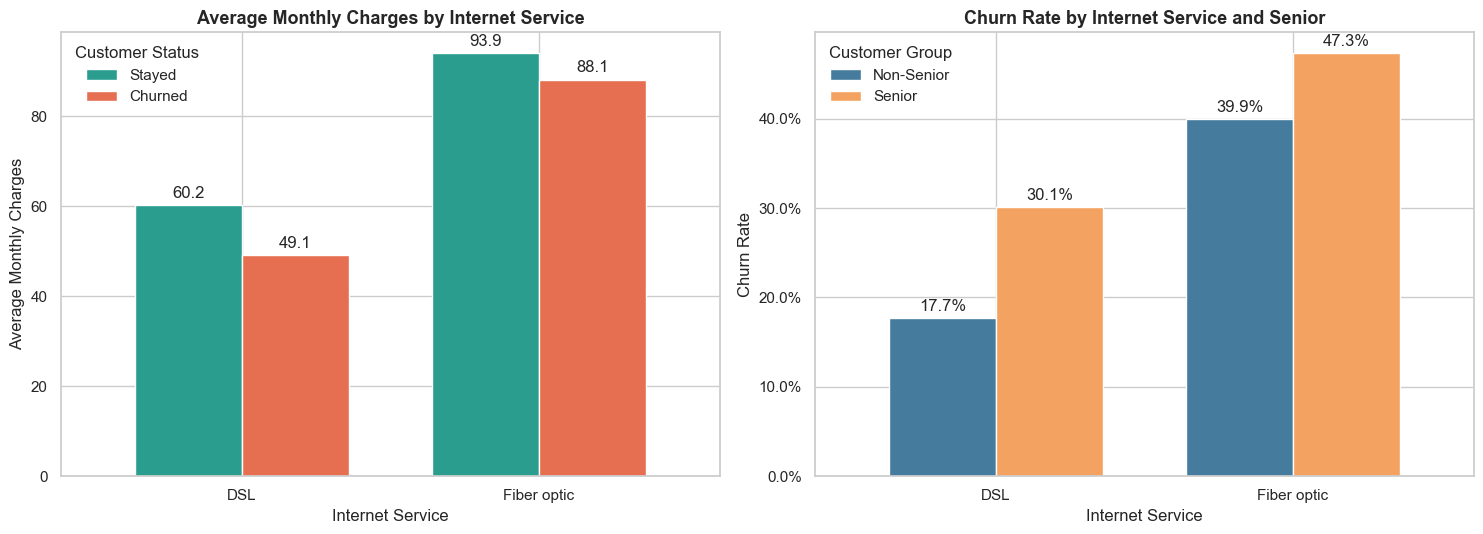

In [20]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")

service_order = ["DSL", "Fiber optic"]

monthly_charges = (
    data.pivot_table(
        index="InternetService",
        columns="Churn",
        values="MonthlyCharges",
        aggfunc="mean"
    )
    .drop(index="No")
    .reindex(service_order)
    .rename(
        columns={
            0: "Stayed",
            1: "Churned"
        }
    )
)

churn_rates = (
    data.pivot_table(
        index="InternetService",
        columns="SeniorCitizen",
        values="Churn",
        aggfunc="mean"
    )
    .mul(100)
    .drop(index="No")
    .reindex(service_order)
    .rename(
        columns={
            0: "Non-Senior",
            1: "Senior"
        }
    )
)

fig, axes = plt.subplots(1,2,figsize=(15, 5.5))

monthly_charges.plot(
    kind="bar",
    ax=axes[0],
    width=0.72,
    color=["#2A9D8F", "#E76F51"],
    edgecolor="white"
)

axes[0].set_title(
    "Average Monthly Charges by Internet Service",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_xlabel("Internet Service")
axes[0].set_ylabel("Average Monthly Charges")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Customer Status", frameon=False)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.1f",
        padding=3
    )

churn_rates.plot(
    kind="bar",
    ax=axes[1],
    width=0.72,
    color=["#457B9D", "#F4A261"],
    edgecolor="white"
)

axes[1].set_title(
    "Churn Rate by Internet Service and Senior",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Internet Service")
axes[1].set_ylabel("Churn Rate")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Customer Group", frameon=False)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()


In [ ]:
from scipy.stats import chi2_contingency

data_test = data[data.InternetService.isin(["DSL" , "Fiber optic"])] # مهم


observed = pd.crosstab(
    data_test["SeniorCitizen"],
    data_test["InternetService"]
)

chi2, p_value, dof, expected = chi2_contingency(observed)

print(observed)
print(f"\nChi-square: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.3e}")
print(f"Expected {expected}")

n = observed.to_numpy().sum()
rows, columns = observed.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)


print(f"Cramer's V: {cramers_v:.3f}")


InternetService   DSL  Fiber optic
SeniorCitizen                     
0                2157         2265
1                 259          831

Chi-square: 221.285
Degrees of freedom: 1
P-value: 4.743e-50
Expected [[1938.23512337 2483.76487663]
 [ 477.76487663  612.23512337]]
Cramer's V: 0.200


In [ ]:
from scipy.stats import mannwhitneyu

test_data = data.loc[
    data["InternetService"].isin(
        ["DSL", "Fiber optic"]
    ),
    ["InternetService", "MonthlyCharges"]
].dropna()

fiber_group = test_data.loc[
    test_data["InternetService"] == "Fiber optic",
    "MonthlyCharges"
]

dsl_group = test_data.loc[
    test_data["InternetService"] == "DSL",
    "MonthlyCharges"
]

# آزمون Mann–Whitney U
u_statistic, p_value = mannwhitneyu(
    fiber_group,
    dsl_group,
    alternative="two-sided",
    method="asymptotic"
)

# اندازه اثر Rank-biserial
rank_biserial = (
    2 * u_statistic
    / (len(fiber_group) * len(dsl_group))
    - 1
)

effect_size = abs(rank_biserial)

print("p-value < 0.001")
print(f"P-value: {p_value}")
print(f"Rank-biserial: {rank_biserial}")





p-value < 0.001
P-value: 0.0
Rank-biserial: 0.8851873866300459


<div dir="rtl">
 نوع اینترنت و هزینه ماهانه ارتباط بسیار قوی دارند و مشتریان Fiber معمولاً هزینه ماهانه بیشتری از مشتریان DSL پرداخت می‌کنند
</div>

- آیا روش پرداخت تاثیری در ترک مشتری دارد ؟ 

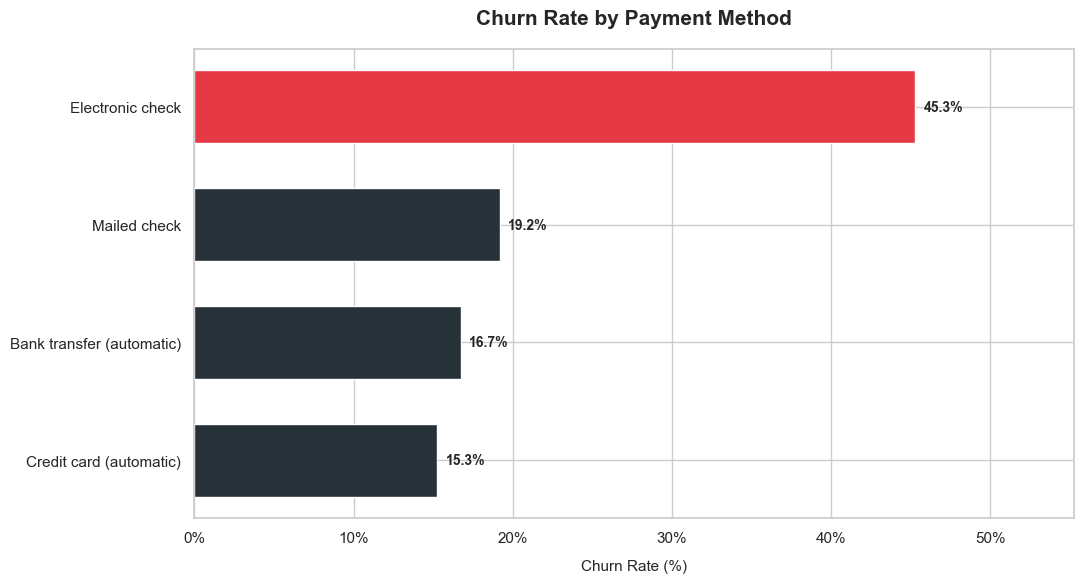

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    font_scale=1
)

# محاسبه نرخ ترک هر روش پرداخت
churn_rate = (
    data.groupby("PaymentMethod")["Churn"]
    .mean()
    .mul(100)
    .sort_values()
)

# بالاترین نرخ قرمز و بقیه مشکی
colors = [
    "#E63946" if value == churn_rate.max() else "#263238"
    for value in churn_rate
]

fig, ax = plt.subplots(
    figsize=(11, 6)
)

bars = ax.barh(
    churn_rate.index,
    churn_rate.values,
    color=colors,
    height=0.62,
    edgecolor="white",
    linewidth=1
)

# نوشتن درصد کنار میله‌ها
ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in churn_rate.values
    ],
    padding=6,
    fontsize=10,
    fontweight="bold"
)

# میانگین کلی نرخ ترک
overall_rate = data["Churn"].mean() * 100

ax.set_title(
    "Churn Rate by Payment Method",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Churn Rate (%)",
    fontsize=11,
    labelpad=10
)

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.set_xlim(
    0,
    churn_rate.max() * 1.22
)


plt.tight_layout()

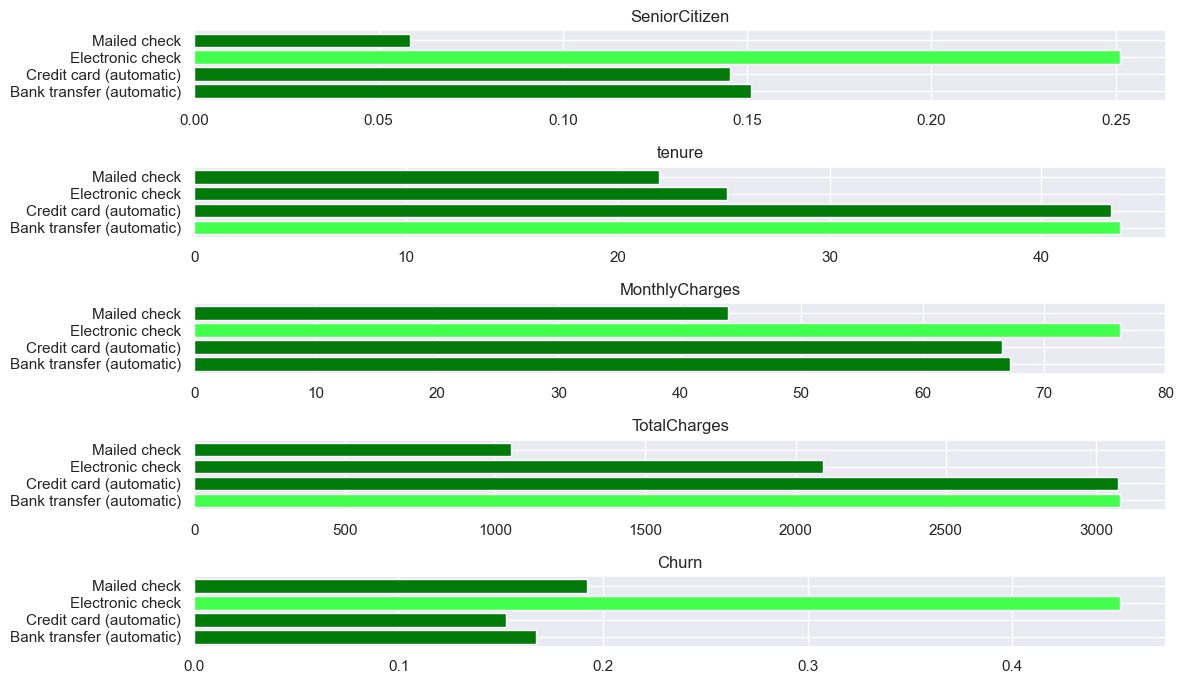

In [38]:
size , axes = plt.subplots(5,1,figsize=[12,7])
axes = axes.flatten()

for i , col in enumerate(data.select_dtypes("number")) : 
    a = data.groupby("PaymentMethod")[col].mean()
    a = a.reset_index()
    axes[i].barh(a.PaymentMethod , a[col] ,
            color=["#42FF4D" if var == a[col].max() else "#007A08" for var in a[col]]
                 )
    axes[i].set_title(col)

plt.tight_layout()

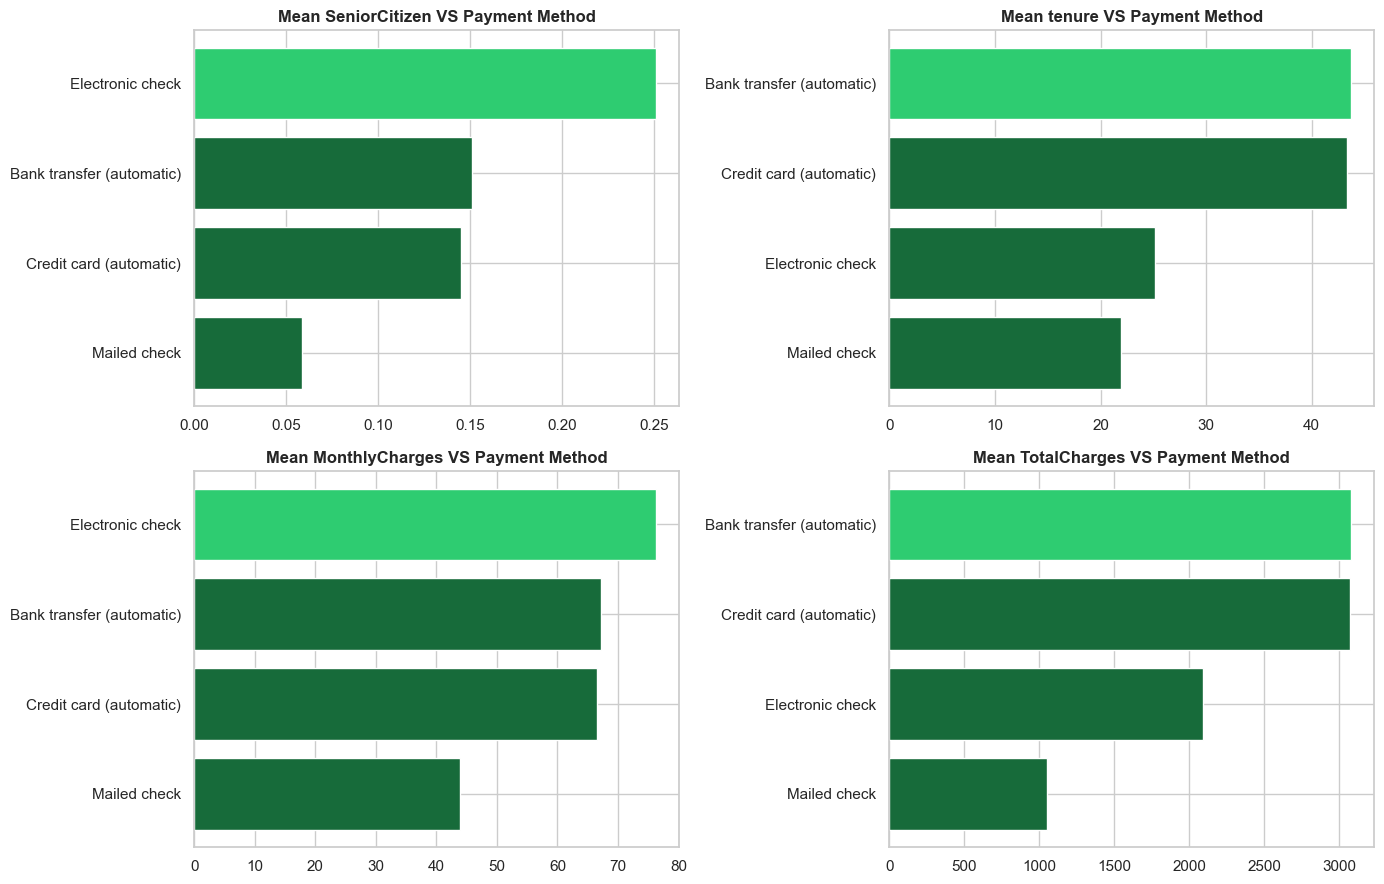

In [71]:
import matplotlib.pyplot as plt

numeric_cols = [
    "SeniorCitizen",
    "tenure" ,
    "MonthlyCharges",
    "TotalCharges" 
    
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):

    result = data.groupby("PaymentMethod")[col].mean().sort_values()
    colors = [
        "#2ecc71" if value == result.max() else "#176b3a"
        for value in result.values
    ]

    ax.barh(result.index, result.values, color=colors)
    ax.set_title(f"Mean {col} VS Payment Method", fontweight="bold")

plt.tight_layout()

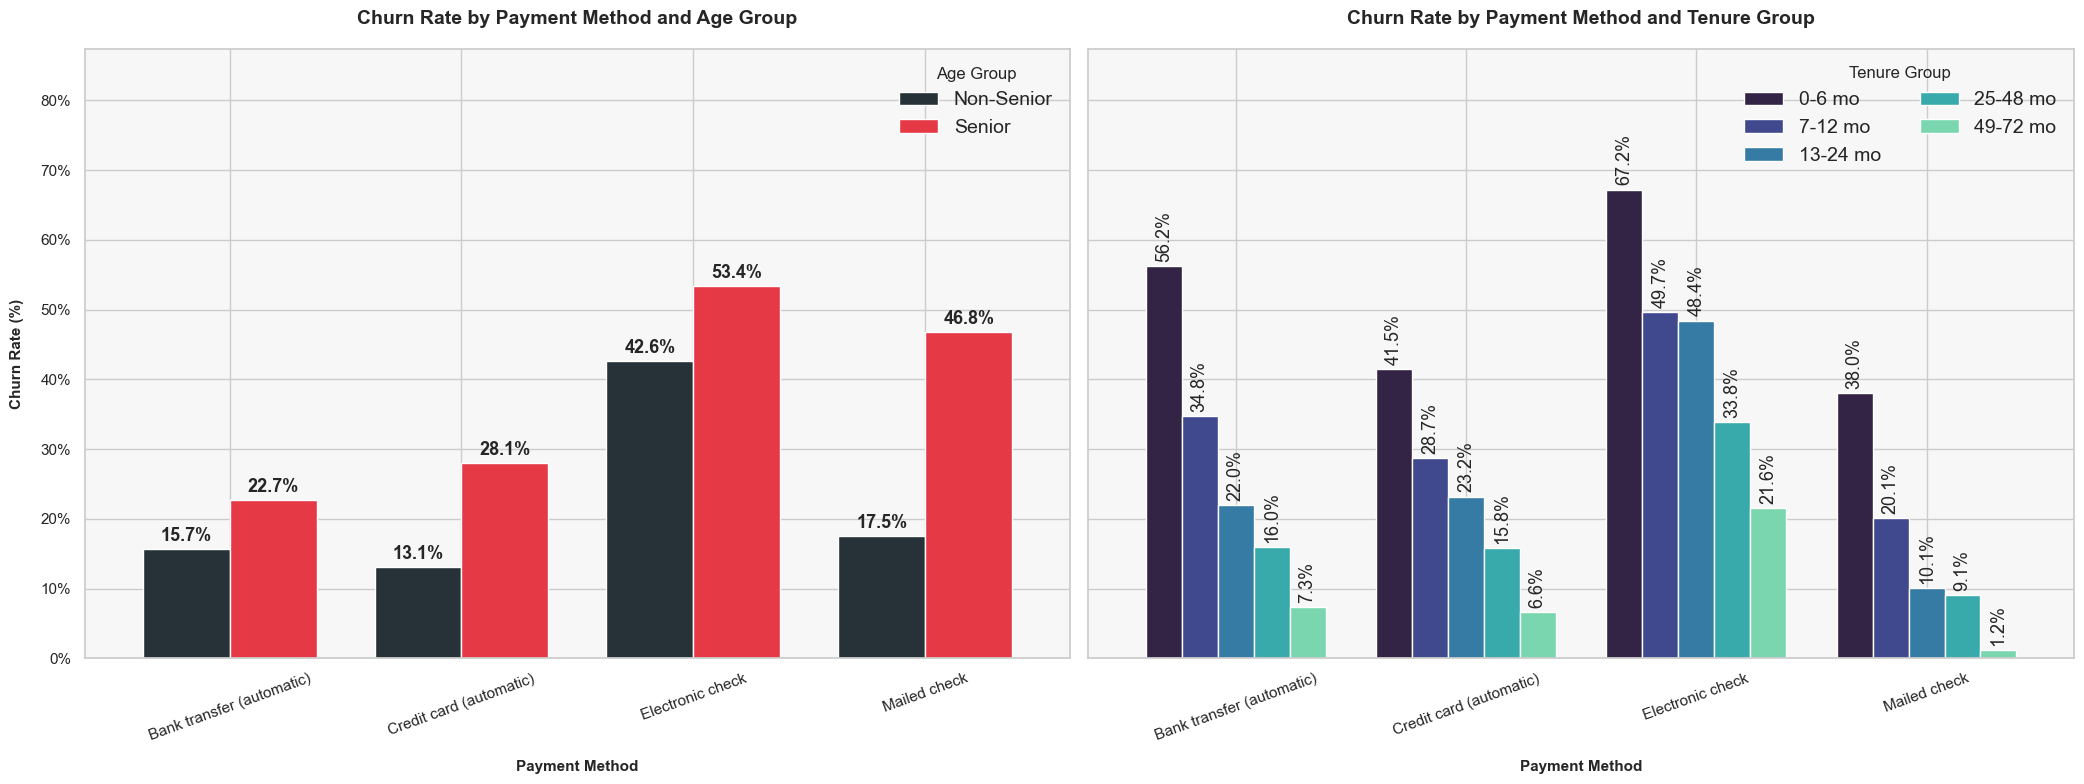

In [72]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#F7F7F7",
        "figure.facecolor": "white"
    }
)

payment_order = [
    "Bank transfer (automatic)",
    "Credit card (automatic)",
    "Electronic check",
    "Mailed check"
]

# نمودار اول: PaymentMethod و SeniorCitizen
payment_age = pd.crosstab(
    index=data["PaymentMethod"],
    columns=data["SeniorCitizen"],
    values=data["Churn"],
    aggfunc="mean"
).mul(100)

payment_age = (
    payment_age.rename(
        columns={
            0: "Non-Senior",
            1: "Senior"
        }
    )
    .reindex(payment_order)
    [["Non-Senior", "Senior"]]
)

# نمودار دوم: PaymentMethod و new_tenure
payment_tenure = pd.crosstab(
    index=data["PaymentMethod"],
    columns=data["new_tenure"],
    values=data["Churn"],
    aggfunc="mean"
).mul(100)

payment_tenure = payment_tenure.reindex(
    payment_order
)

# ساخت دو نمودار کنار یکدیگر
fig, axes = plt.subplots(
    1,
    2,
    figsize=(21, 8),
    sharey=True
)

# نمودار سمت چپ
payment_age.plot(
    kind="bar",
    ax=axes[0],
    width=0.75,
    color=["#263238", "#E63946"],
    edgecolor="white",
    linewidth=1
)

# رنگ‌های نمودار سمت راست
tenure_colors = sns.color_palette(
    "mako",
    n_colors=len(payment_tenure.columns)
)

payment_tenure.plot(
    kind="bar",
    ax=axes[1],
    width=0.78,
    color=tenure_colors,
    edgecolor="white",
    linewidth=1
)

# میانگین کلی نرخ ترک
overall_rate = data["Churn"].mean() * 100

for ax in axes:

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.set_xlabel(
        "Payment Method",
        fontsize=11,
        fontweight="bold",
        labelpad=12
    )

    ax.set_ylabel("")

    ax.tick_params(
        axis="x",
        rotation=20
    )

# عنوان نمودار سمت چپ
axes[0].set_title(
    "Churn Rate by Payment Method and Age Group",
    fontsize=14,
    fontweight="bold",
    pad=18
)

axes[0].set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

# عنوان نمودار سمت راست
axes[1].set_title(
    "Churn Rate by Payment Method and Tenure Group",
    fontsize=14,
    fontweight="bold",
    pad=18
)

# نوشتن مقدار روی میله‌های نمودار اول
for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=13,
        fontweight="bold"
    )

# نوشتن مقدار روی میله‌های نمودار دوم
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=13,
        rotation=90
    )

# یکسان‌کردن محدوده محور عمودی
maximum_rate = max(
    payment_age.max().max(),
    payment_tenure.max().max()
)

axes[0].set_ylim(
    0,
    min(100, maximum_rate * 1.3)
)

axes[0].legend(
    title="Age Group",
    frameon=False,
    fontsize=14
)

axes[1].legend(
    title="Tenure Group",
    frameon=False,
    fontsize=14,
    ncol=2
)

plt.tight_layout()

In [8]:
from scipy.stats import chi2_contingency

observed = pd.crosstab(
    data["SeniorCitizen"],
    data["PaymentMethod"]
)

chi2, p_value, dof, expected = chi2_contingency(observed)

# print(observed)
print(f"\nChi-square: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.3e}")
print(f"Expected {expected}")

n = observed.to_numpy().sum()
rows, columns = observed.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)


print(f"Cramer's V: {cramers_v:.3f}")



Chi-square: 268.742
Degrees of freedom: 3
P-value: 5.775e-58
Expected [[1291.57849829 1273.98890785 1980.92292378 1343.50967008]
 [ 250.42150171  247.01109215  384.07707622  260.49032992]]
Cramer's V: 0.195


- آزمون Kruskal–Wallis
    - برای مقایسه یک متغیر عددی غیرنرمال بین سه گروه مستقل یا بیشتر
    - فرض صفر: توزیع متغیر عددی در تمام گروه‌ها یکسان است.
    - Epsilon Squared: اندازه اثر یا شدت تفاوت بین گروه‌ها
        - 0.01 → اثر ضعیف
        - 0.06 → اثر متوسط
        - 0.14 → اثر بزرگ

In [ ]:
from scipy.stats import kruskal

test_data = data[
    ["PaymentMethod", "tenure"]
].dropna()

groups = {
    method: group["tenure"].to_numpy()
    for method, group in test_data.groupby("PaymentMethod")
}

h_statistic, p_value = kruskal(
    *groups.values()
)

print(f"H-statistic: {h_statistic:.3f}")
print(f"P-value: {p_value:.3e}")

number_of_groups = len(groups)
n = len(test_data)

epsilon_squared = max(
    0,
    (h_statistic - number_of_groups + 1) / (n - number_of_groups)
)

print(f"Epsilon squared: {epsilon_squared:.3f}")


H-statistic: 1156.995
P-value: 1.569e-250
Epsilon squared: 0.164


- آیا نداشتن پشتیبان آنلاین و امنیت آنلاین باعث ترک بیشتر میشود ؟ 

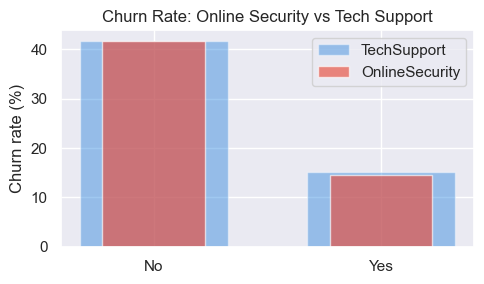

In [ ]:
data_copy = data.copy()
data_copy = data_copy[data_copy.OnlineSecurity != "No internet service"]

order = ["No" , "Yes"]

a = data_copy.groupby("OnlineSecurity").Churn.mean() * 100
b = data_copy.groupby("TechSupport").Churn.mean() * 100

plt.figure(figsize=(5, 3))

plt.bar(
    order,
    b,
    color="#2E86DE",
    alpha=0.45,
    width=0.65,
    label="TechSupport"
)

plt.bar(
    order,
    a,
    color="#E74C3C",
    alpha=0.65,
    width=0.45,
    label="OnlineSecurity"
)

plt.title("Churn Rate: Online Security vs Tech Support")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.tight_layout()

- آیا خود پشتیبان فنی و امنیت آنلاین باعث ترک کمتر شده یا عوامل پنهانی وجود دارد

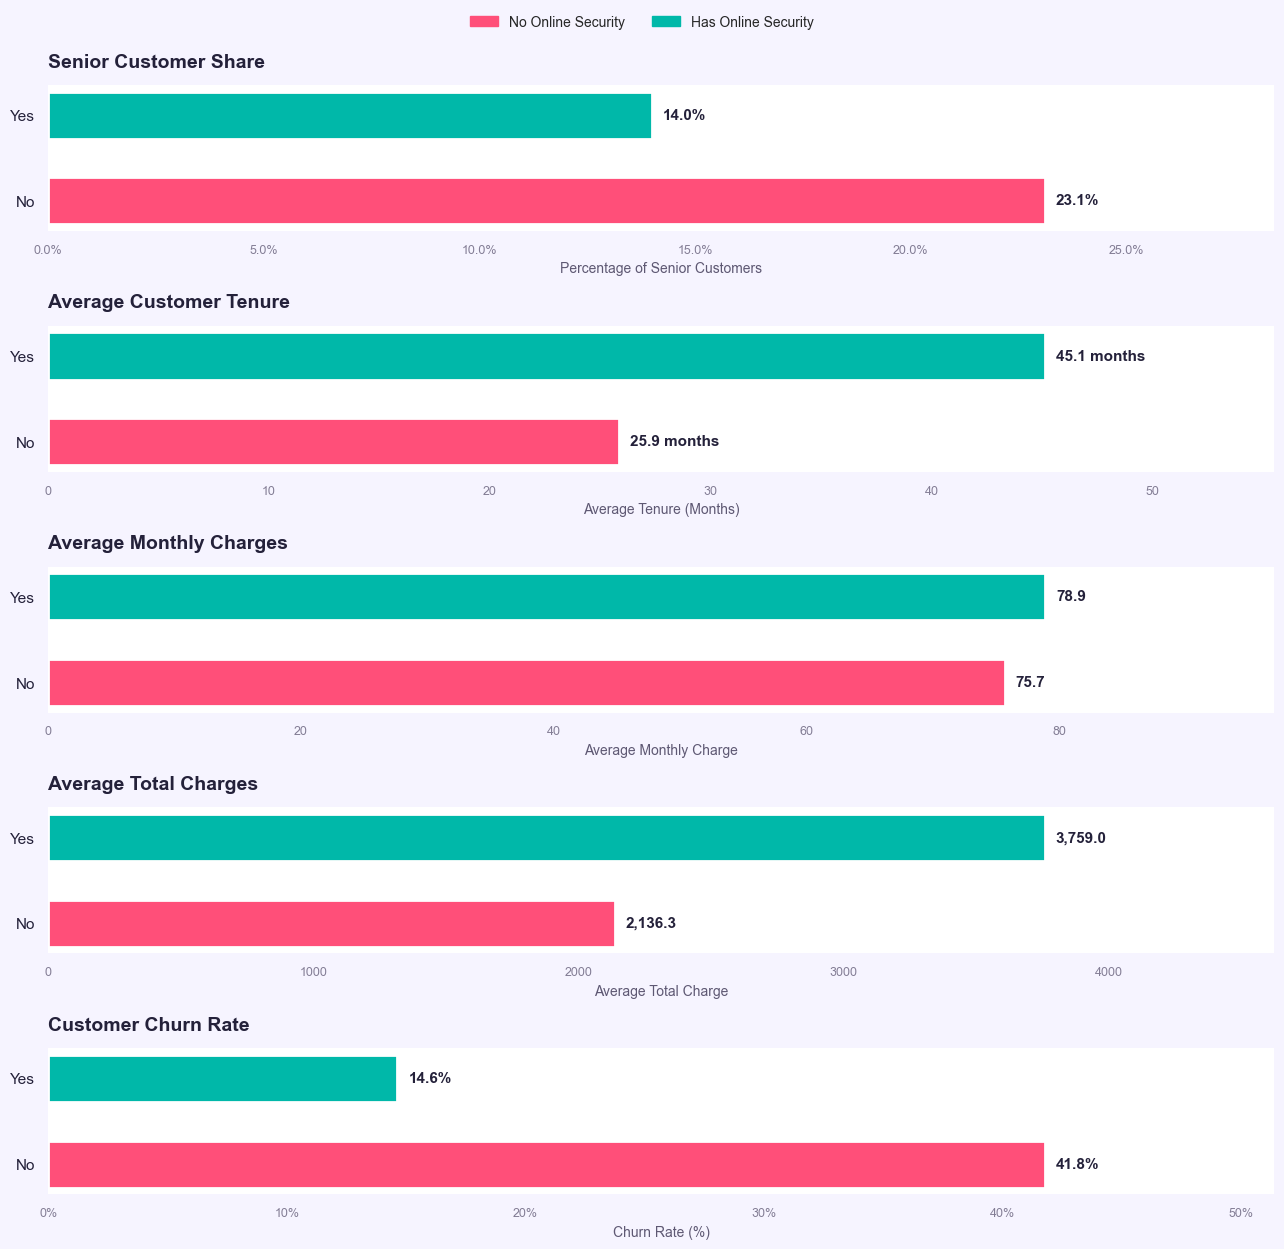

In [27]:
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

sns.set_theme(style="white")

# فقط مشتریانی که اینترنت دارند
online_users = data[
    data["OnlineSecurity"].isin(["No", "Yes"])
].copy()

plot_settings = [
    (
        "SeniorCitizen",
        "Senior Customer Share",
        "Percentage of Senior Customers",
        "percent"
    ),
    (
        "tenure",
        "Average Customer Tenure",
        "Average Tenure (Months)",
        "months"
    ),
    (
        "MonthlyCharges",
        "Average Monthly Charges",
        "Average Monthly Charge",
        "number"
    ),
    (
        "TotalCharges",
        "Average Total Charges",
        "Average Total Charge",
        "number"
    ),
    (
        "Churn",
        "Customer Churn Rate",
        "Churn Rate (%)",
        "percent"
    )
]

palette = {
    "No": "#FF4F79",   # صورتی مرجانی
    "Yes": "#00B8A9"   # سبز اقیانوسی
}

fig, axes = plt.subplots(
    5,
    1,
    figsize=(13, 13),
    facecolor="#F6F4FF"
)

axes = axes.flatten()

for ax, (
    column,
    title,
    xlabel,
    value_type
) in zip(axes, plot_settings):

    result = (
        online_users.groupby("OnlineSecurity")[column]
        .mean()
        .reindex(["No", "Yes"])
    )

    colors = [
        palette[group]
        for group in result.index
    ]

    bars = ax.barh(
        result.index,
        result.values,
        height=0.55,
        color=colors,
        edgecolor="white",
        linewidth=2
    )

    # فرمت مناسب اعداد
    if value_type == "percent":

        labels = [
            f"{value:.1%}"
            for value in result.values
        ]

        ax.xaxis.set_major_formatter(
            PercentFormatter(xmax=1)
        )

    elif value_type == "months":

        labels = [
            f"{value:.1f} months"
            for value in result.values
        ]

    else:

        labels = [
            f"{value:,.1f}"
            for value in result.values
        ]

    # نوشتن مقدار کنار میله‌ها
    ax.bar_label(
        bars,
        labels=labels,
        padding=8,
        fontsize=11,
        fontweight="bold",
        color="#24213A"
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        color="#24213A",
        pad=13,
        loc="left"
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10,
        color="#5E5873"
    )

    ax.set_ylabel("")

    ax.set_xlim(
        0,
        result.max() * 1.23
    )

    ax.set_facecolor("#FFFFFF")

    ax.tick_params(
        axis="x",
        colors="#837D95",
        labelsize=9
    )

    ax.tick_params(
        axis="y",
        colors="#24213A",
        labelsize=11
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

# راهنمای مشترک
fig.legend(
    handles=[
        Patch(
            color=palette["No"],
            label="No Online Security"
        ),
        Patch(
            color=palette["Yes"],
            label="Has Online Security"
        )
    ],
    loc="upper center",
    ncol=2,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(0.5, 0.965)
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)



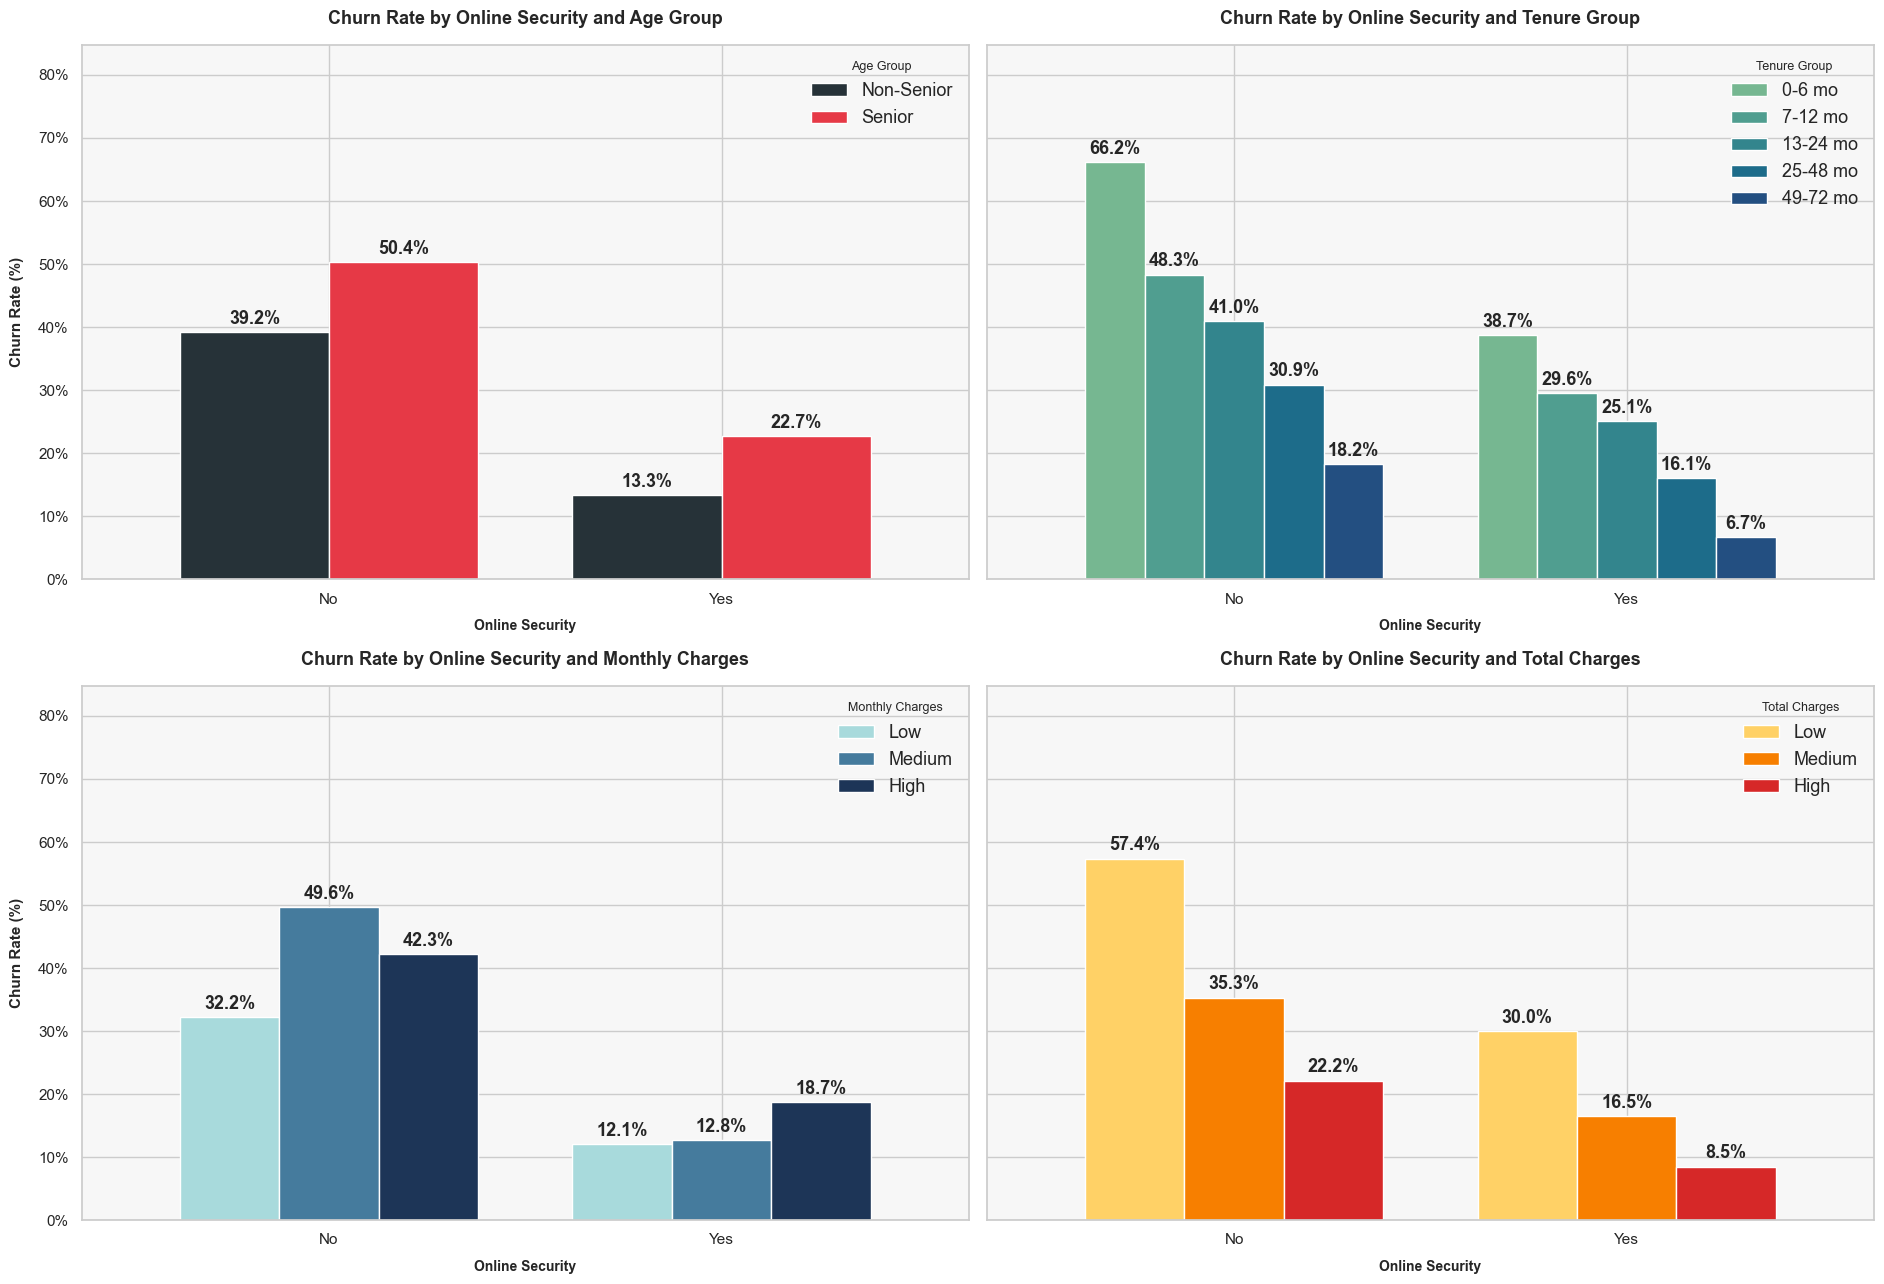

In [ ]:

from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#F7F7F7",
        "figure.facecolor": "white"
    }
)

# حذف مشتریانی که اصلاً اینترنت ندارند
plot_data = data.loc[
    data["OnlineSecurity"] != "No internet service"
].copy()

# تبدیل هزینه‌های عددی به سه گروه کم، متوسط و زیاد
plot_data["MonthlyCharges_Group"] = pd.qcut(
    plot_data["MonthlyCharges"],
    q=3,
    labels=["Low", "Medium", "High"]
)

plot_data["TotalCharges_Group"] = pd.qcut(
    plot_data["TotalCharges"],
    q=3,
    labels=["Low", "Medium", "High"]
)


# تابع ساخت جدول نرخ Churn
def create_churn_table(group_column, rename_columns=None):

    table = plot_data.pivot_table(
        index="OnlineSecurity",
        columns=group_column,
        values="Churn",
        aggfunc="mean",
        observed=False
    ).mul(100)

    # ترتیب سطرها
    table = table.reindex(["No", "Yes"])

    if rename_columns is not None:
        table = table.rename(
            columns=rename_columns
        )

    return table


# ۱. OnlineSecurity و SeniorCitizen
senior_table = create_churn_table(
    "SeniorCitizen",
    rename_columns={
        0: "Non-Senior",
        1: "Senior"
    }
)

# ۲. OnlineSecurity و گروه tenure
tenure_table = create_churn_table(
    "new_tenure"
)

# ۳. OnlineSecurity و MonthlyCharges
monthly_table = create_churn_table(
    "MonthlyCharges_Group"
)

# ۴. OnlineSecurity و TotalCharges
total_table = create_churn_table(
    "TotalCharges_Group"
)


tables = [
    senior_table,
    tenure_table,
    monthly_table,
    total_table
]

titles = [
    "Churn Rate by Online Security and Age Group",
    "Churn Rate by Online Security and Tenure Group",
    "Churn Rate by Online Security and Monthly Charges",
    "Churn Rate by Online Security and Total Charges"
]

legend_titles = [
    "Age Group",
    "Tenure Group",
    "Monthly Charges",
    "Total Charges"
]

palettes = [
    ["#263238", "#E63946"],
    sns.color_palette("crest", n_colors=len(tenure_table.columns)),
    ["#A8DADC", "#457B9D", "#1D3557"],
    ["#FFD166", "#F77F00", "#D62828"]
]


# ساخت چهار نمودار در چیدمان ۲×۲
fig, axes = plt.subplots(
    2,
    2,
    figsize=(19, 13),
    sharey=True
)

axes = axes.flatten()

# میانگین کلی نرخ ترک
overall_churn = plot_data["Churn"].mean() * 100

# بیشترین مقدار برای یکسان‌کردن محور عمودی
maximum_rate = max(
    np.nanmax(table.to_numpy())
    for table in tables
)

upper_limit = min(
    100,
    maximum_rate * 1.28
)


for ax, table, title, legend_title, colors in zip(
    axes,
    tables,
    titles,
    legend_titles,
    palettes
):

    table.plot(
        kind="bar",
        ax=ax,
        width=0.76,
        color=colors,
        edgecolor="white",
        linewidth=1
    )

    # نوشتن درصد روی میله‌ها
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3,
            fontsize=13,
            fontweight="bold"
        )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Online Security",
        fontsize=10,
        fontweight="bold",
        labelpad=9
    )

    ax.set_ylabel("")

    ax.set_ylim(
        0,
        upper_limit
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )


    ax.legend(
        title=legend_title,
        frameon=False,
        fontsize=13,
        title_fontsize=9
    )


axes[0].set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

axes[2].set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)


plt.tight_layout()


- نتیجه گیری کلی 

In [ ]:
from scipy.stats import chi2_contingency

test_data = data[data.DeviceProtection.isin(["Yes" , "No"])] # مهم

observed = pd.crosstab(
    test_data["SeniorCitizen"],
    test_data["DeviceProtection"]
)

chi2, p_value, dof, expected = chi2_contingency(observed)
print(f"P-value: {p_value:.3e}")


n = observed.to_numpy().sum()
rows, columns = observed.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)


print(f"Cramer's V: {cramers_v:.3f}")   

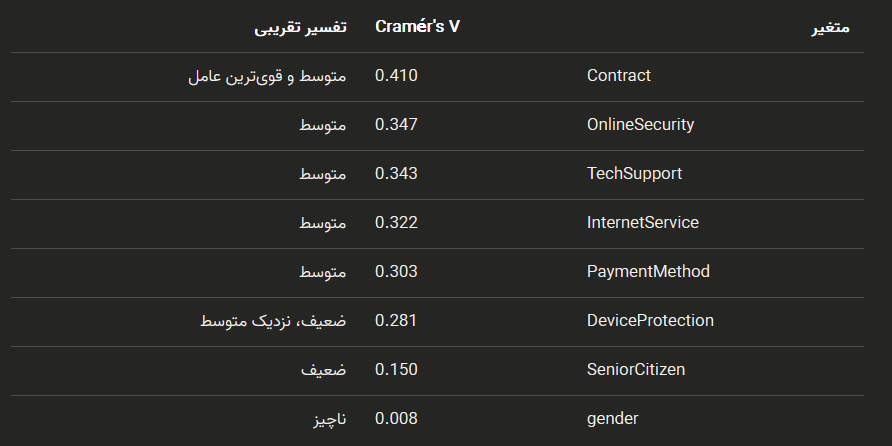

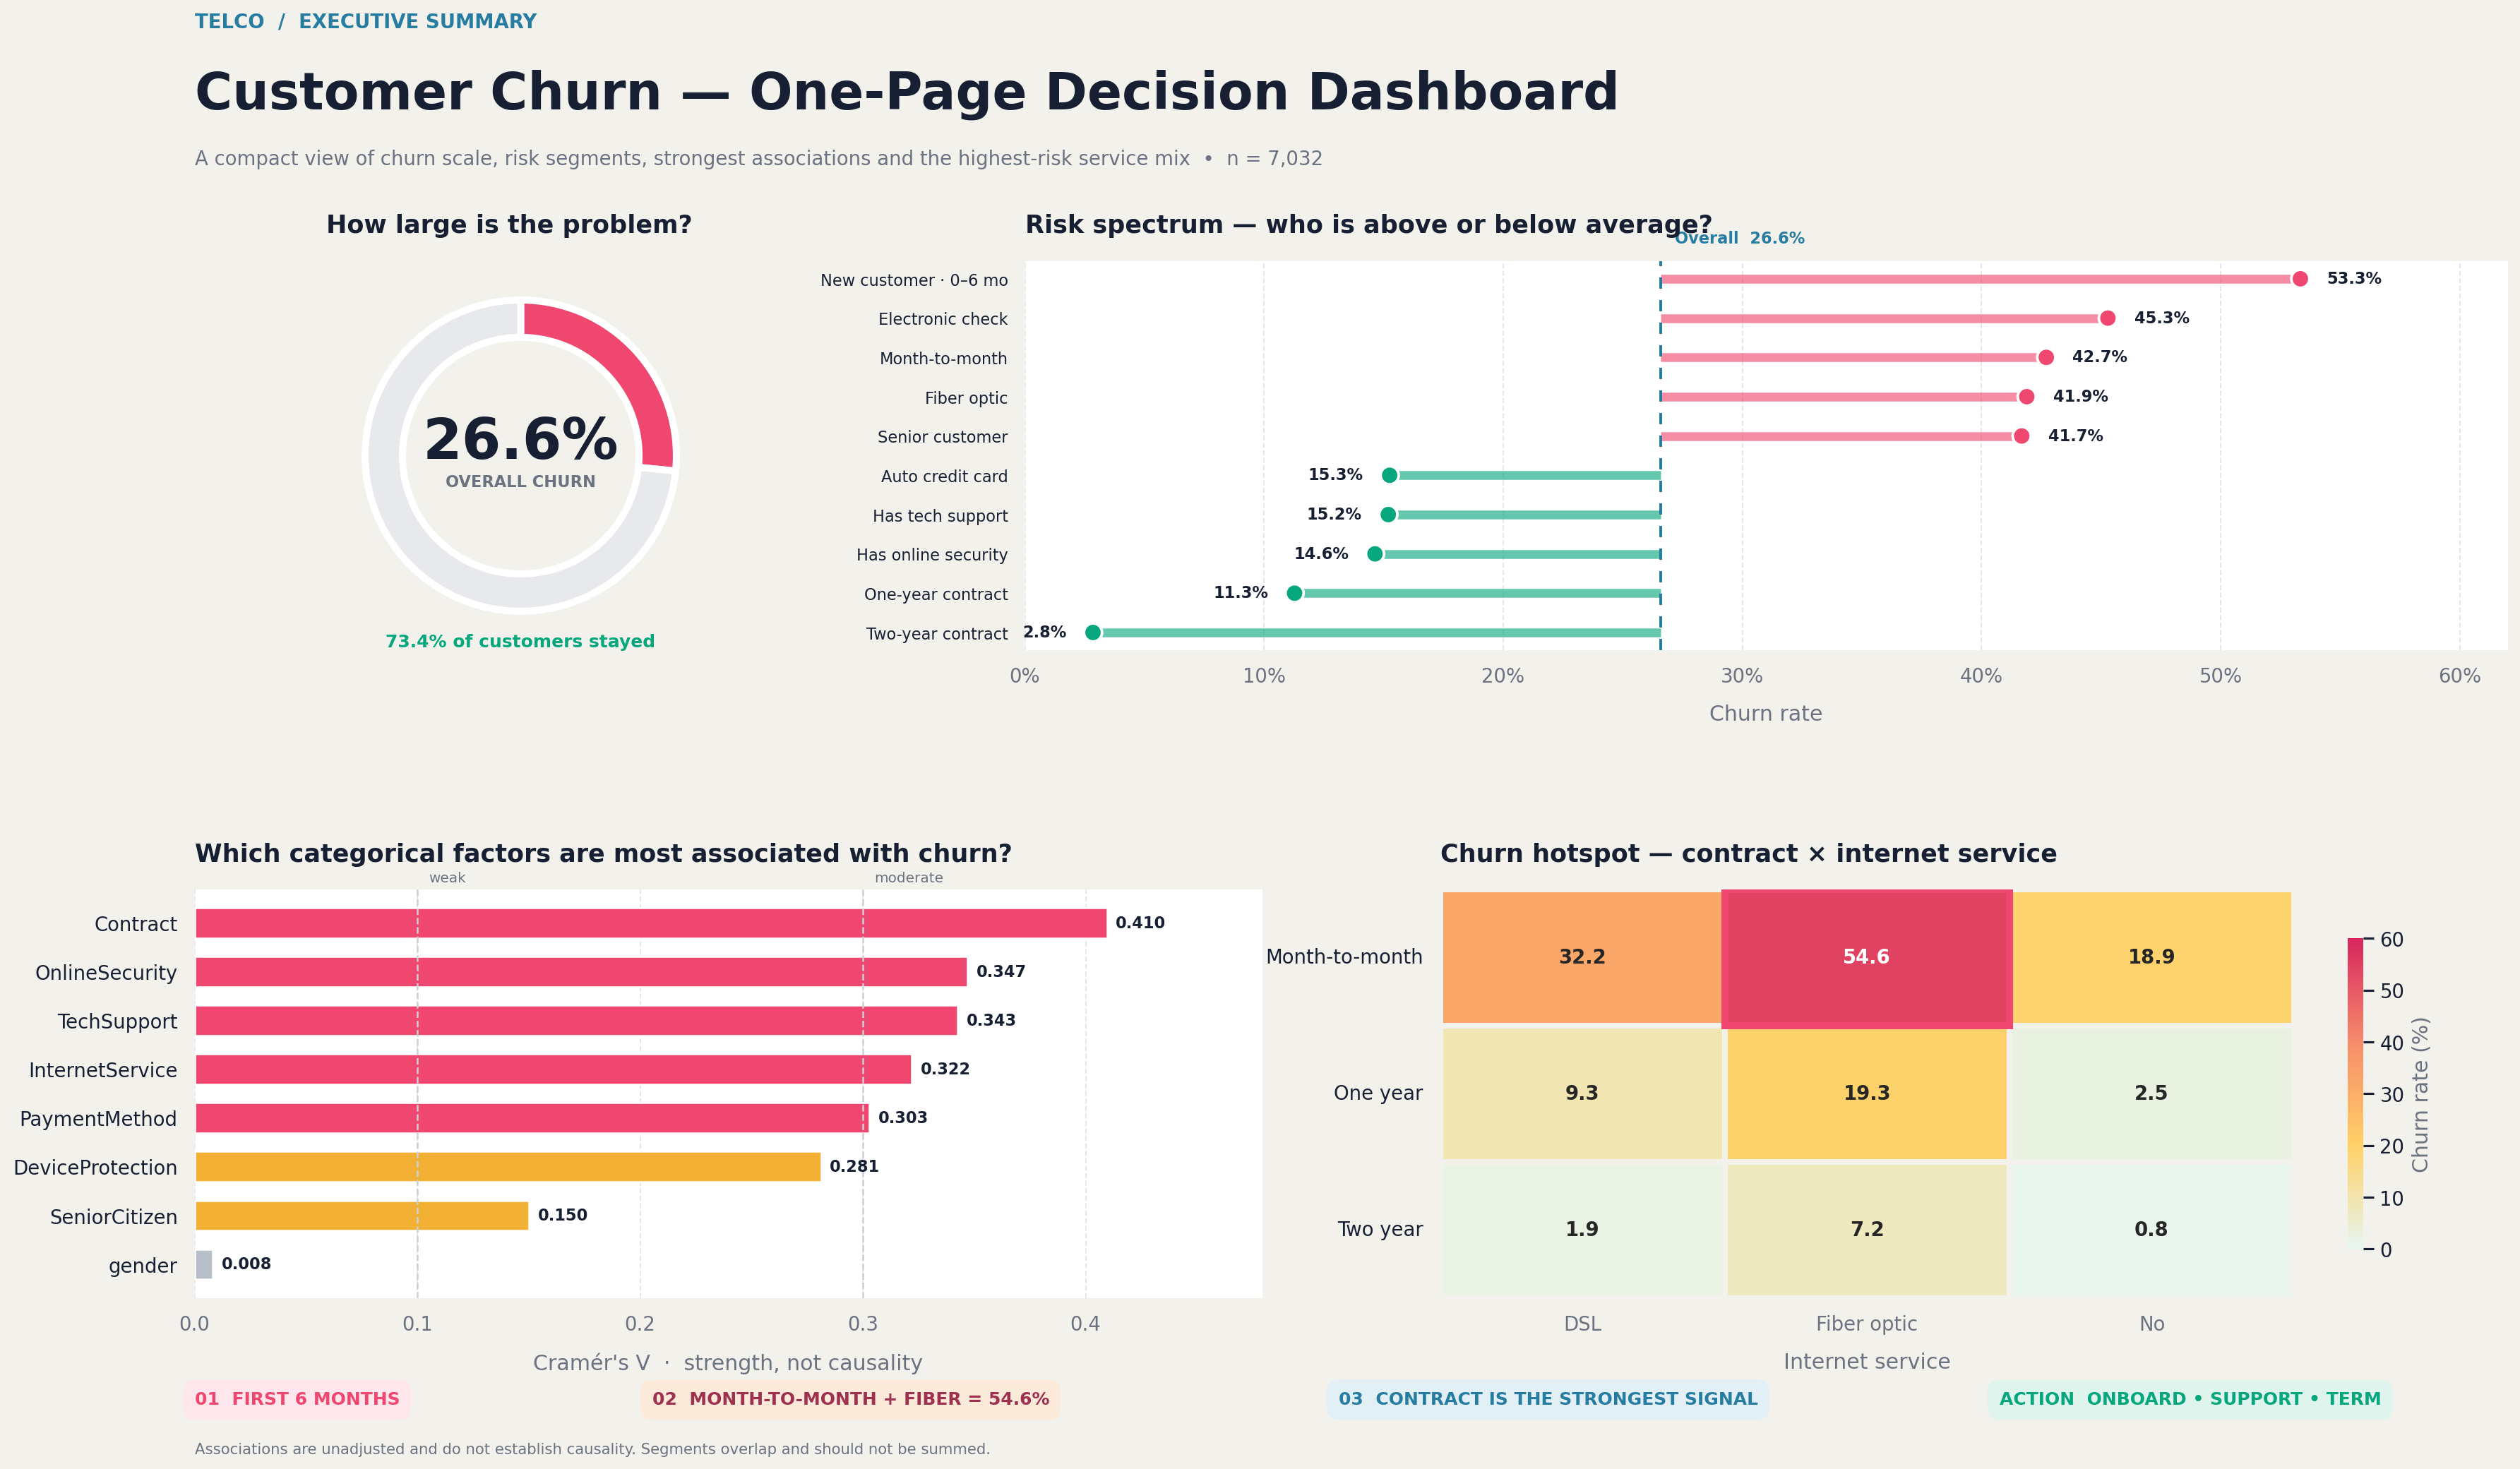

# https://clever-bubblegum-23cfad.netlify.app/